# Data Exploration + Preprocessing: <YOUR NAME>

**How to use this template**
1. **Do not edit this template.** Make a copy, rename it to `eda/eda_<yourname>.ipynb`, and work only in your copy.
2. Run the cells group by group. Under each group, write your findings in the **Findings** cell.
3. In section 8, add at least one analysis of your own.
4. At the end, fill in the decision table (one row per feature) and save it. This table is what we compare in the team meeting.
5. Upload your notebook and your CSV to the `exploration` branch (see README). Deadline: 11 October, 10:00 (German time).

**Rules**
- Use only the training split (`load_train()`, 80% of the data). Never look at the test split.
- Do not change `src/` without telling the team; everyone relies on it.

**Guiding questions for every group**
- Distribution: skewed? many zeros? strange values (negative, extreme, placeholder like 0 / "Unknown")?
- Missing values: how many, and how should they be handled?
- Relation to churn: does the churn rate change across values?
- Redundancy: are some columns highly correlated or derived from each other?
- Preprocessing: keep or drop? impute how? transform (log, clip, binarise)? encode how?
- Feature engineering: which new features could be useful?

In [2]:
!git clone -b exploration https://github.com/97-serena/Data-Mining-Project.git
%cd /content/Data-Mining-Project

Cloning into 'Data-Mining-Project'...
remote: Enumerating objects: 93, done.
remote: Counting objects: 100% (93/93), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 93 (delta 39), reused 77 (delta 26), pack-reused 0 (from 0)
Receiving objects: 100% (93/93), 4.53 MiB | 17.36 MiB/s, done.
Resolving deltas: 100% (39/39), done.
/content/Data-Mining-Project


In [3]:
!ls

dataset  eda  README.md  requirements.txt  src


In [4]:
import sys
sys.path.append(".")

import pandas as pd
from src.data import load_train
from src.eda_utils import (FEATURE_GROUPS, overview, churn_signal, churn_rate_by,
                           plot_column, corr_heatmap, summary_skeleton)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

train = load_train()
print(train.shape)
print("churn rate:", round(train["churn"].mean(), 4))

(40837, 59)
churn rate: 0.2882


- **Class weights:** tell the model to penalize mistakes on churners more heavily. This is often a very clean solution.
- **Random oversampling:** duplicate minority-class churn cases.
- **SMOTE:** create synthetic minority-class examples by interpolating between existing churn observations.
- **Undersampling:** remove some majority-class non-churn observations.
- **Hybrid methods:** combine over- and undersampling.

## 0. Overview of all features

In [5]:
all_cols = [c for cols in FEATURE_GROUPS.values() for c in cols]
overview(train, all_cols)

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
MonthlyRevenue,numeric,11624,0.29,NaN,0.01,0.01,-6.17,48.47,228.3256,1223.38,None
TotalRecurringCharge,numeric,207,0.29,NaN,0.34,0.02,-11.00,45.00,120.0000,400.00,None
OverageMinutes,numeric,704,0.29,NaN,45.59,0.00,0.00,3.00,434.0000,4321.00,None
MonthsInService,numeric,56,0.00,NaN,0.00,0.00,6.00,16.00,49.0000,61.00,None
CurrentEquipmentDays,numeric,1397,0.00,NaN,0.04,0.13,-5.00,329.00,1141.6500,1812.00,None
Handsets,numeric,22,0.00,NaN,0.00,0.00,1.00,1.00,7.0000,24.00,None
HandsetModels,numeric,13,0.00,NaN,0.00,0.00,1.00,1.00,5.0000,15.00,None
UniqueSubs,numeric,14,0.00,NaN,0.00,0.00,1.00,1.00,5.0000,18.00,None
ActiveSubs,numeric,10,0.00,NaN,0.08,0.00,0.00,1.00,4.0000,9.00,None


- **OverageMinutes** is very zero-heavy (~45.6%), meaning many customers never exceed their included minutes.
- **ReferralsMadeBySubscriber** is extremely sparse, with ~95% zeros
- **NewCellphoneUser and NotNewCellphoneUser** look potentially redundant and should be checked against each other.
- **RoamingCalls** is ~68.7% zero, **ThreewayCalls** ~72.7% zero, and **CallForwardingCalls** ~99.6% zero. These may need transformations or binary “used/not used” features later.
- **PercChangeMinutes, PercChangeRevenues:** They have small missingness (~0.71%) but very large extremes, suggesting outliers or highly skewed change behavior.
- **Service Quality & Customer Support** especially interesting for churn because they represent possible service frustration. More than half of customers have zero CustomerCareCalls. We should later compare these directly against churn.
- **Retention & Account Intervention** timing and possible leakage: were these actions taken before the prediction point, or only after a customer showed clear intent to leave?
- **Demographic & Socioeconomic Profile** laceholder/unknown information
- **ServiceArea** has 729 unique categories, so it is a high-cardinality categorical variable and may need special encoding or grouping.
- **Marketing / Mail Behavior** how responsive or disengaged a customer is.

https://docs.google.com/document/d/1i0Zm1fRMpuhy5Qqd8d8CX4s1gwQtSmA9PzEwa1Ktt6k/edit?usp=sharing




## 1. Account & billing

Columns: `MonthlyRevenue`, `TotalRecurringCharge`, `OverageMinutes`, `MonthsInService`, `CurrentEquipmentDays`, `Handsets`, `HandsetModels`, `UniqueSubs`, `ActiveSubs`, `AdjustmentsToCreditRating`

In [8]:
cols = FEATURE_GROUPS["account_billing"]
display(overview(train, cols))
display(churn_signal(train, cols))

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
MonthlyRevenue,numeric,11624,0.29,None,0.01,0.01,-6.17,48.47,228.3256,1223.38,None
TotalRecurringCharge,numeric,207,0.29,None,0.34,0.02,-11.00,45.00,120.0000,400.00,None
OverageMinutes,numeric,704,0.29,None,45.59,0.00,0.00,3.00,434.0000,4321.00,None
MonthsInService,numeric,56,0.00,None,0.00,0.00,6.00,16.00,49.0000,61.00,None
CurrentEquipmentDays,numeric,1397,0.00,None,0.04,0.13,-5.00,329.00,1141.6500,1812.00,None
Handsets,numeric,22,0.00,None,0.00,0.00,1.00,1.00,7.0000,24.00,None
HandsetModels,numeric,13,0.00,None,0.00,0.00,1.00,1.00,5.0000,15.00,None
UniqueSubs,numeric,14,0.00,None,0.00,0.00,1.00,1.00,5.0000,18.00,None
ActiveSubs,numeric,10,0.00,None,0.08,0.00,0.00,1.00,4.0000,9.00,None


,auc,signal
column,,
MonthlyRevenue,0.485,0.015
TotalRecurringCharge,0.457,0.043
OverageMinutes,0.511,0.011
MonthsInService,0.528,0.028
CurrentEquipmentDays,0.576,0.076
Handsets,0.482,0.018
HandsetModels,0.479,0.021
UniqueSubs,0.524,0.024
ActiveSubs,0.511,0.011


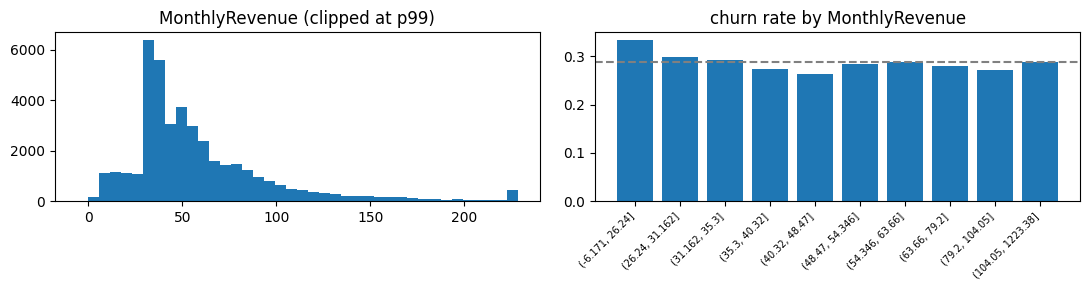

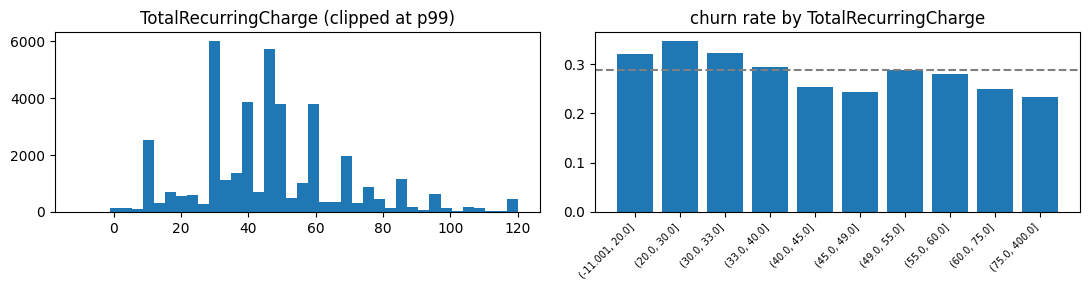

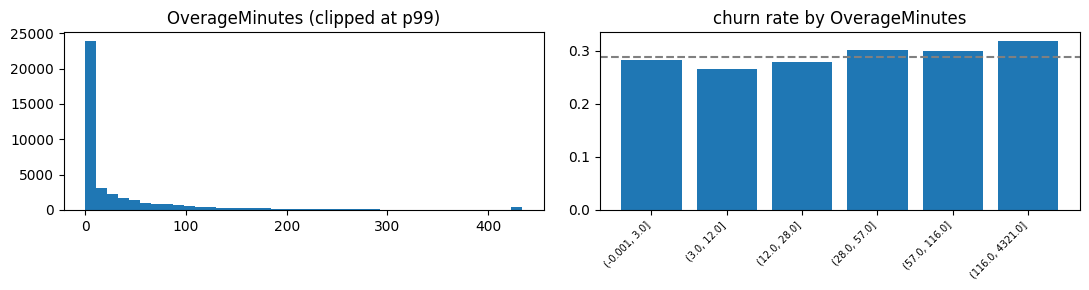

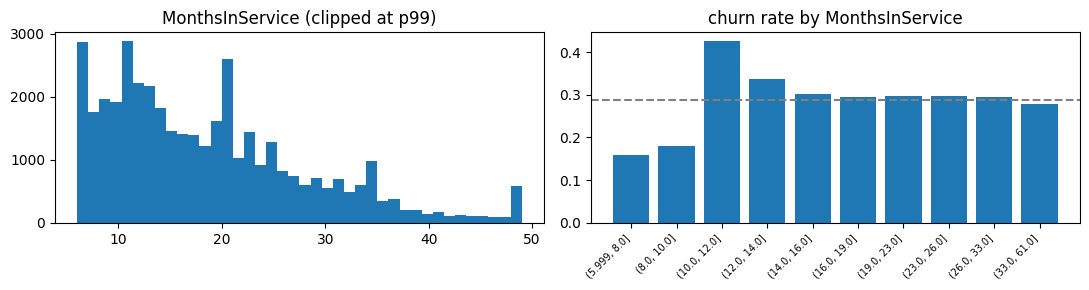

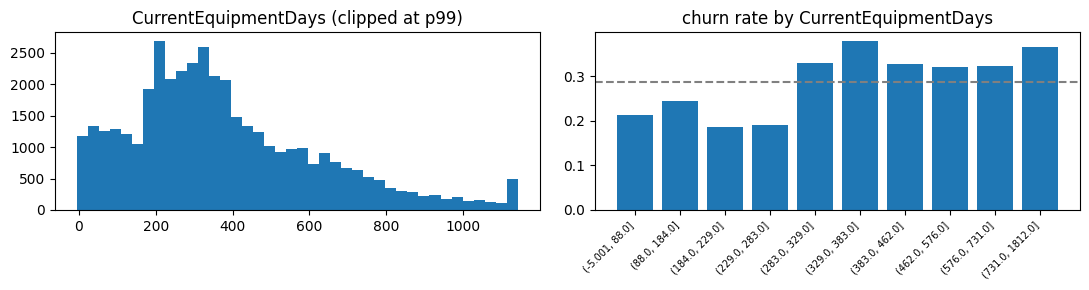

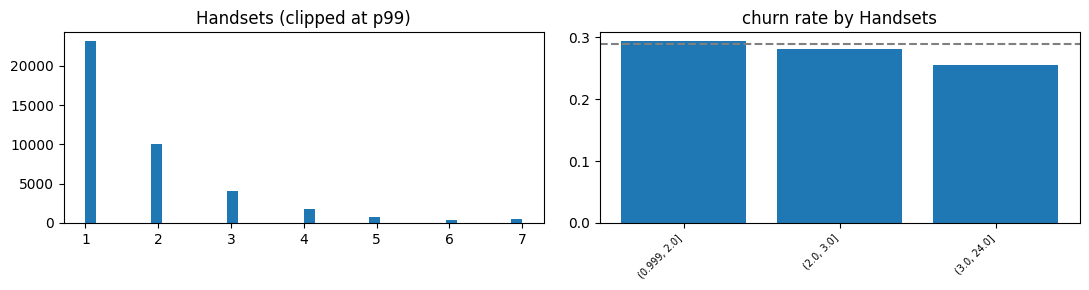

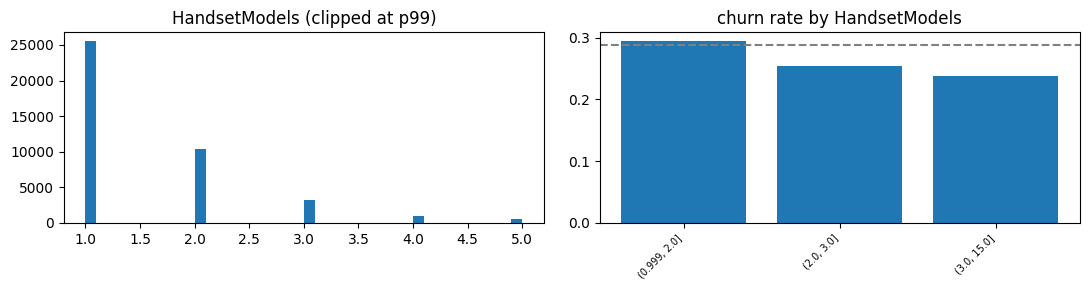

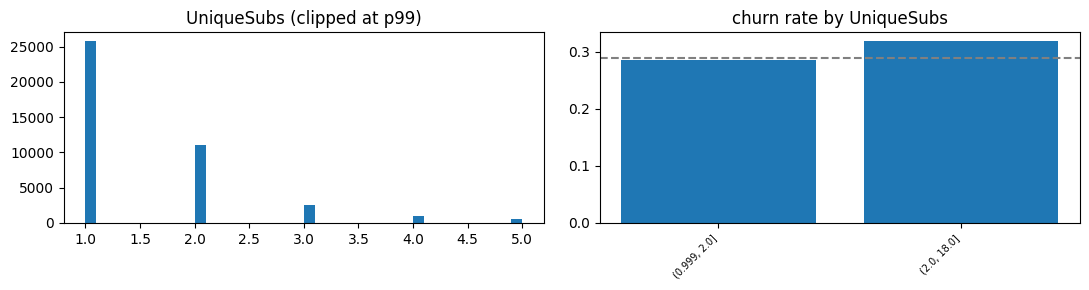

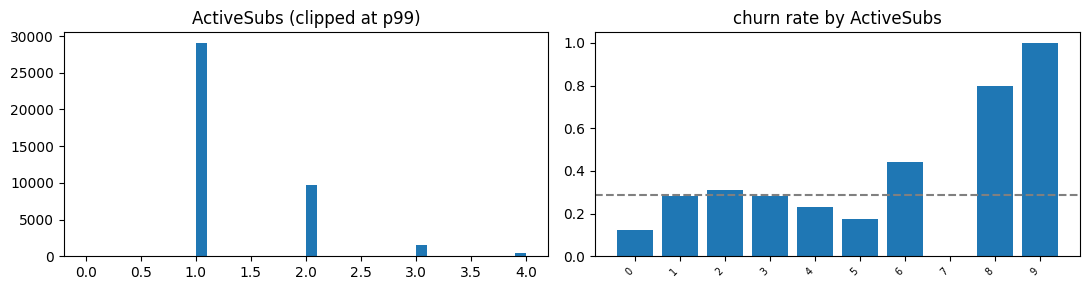

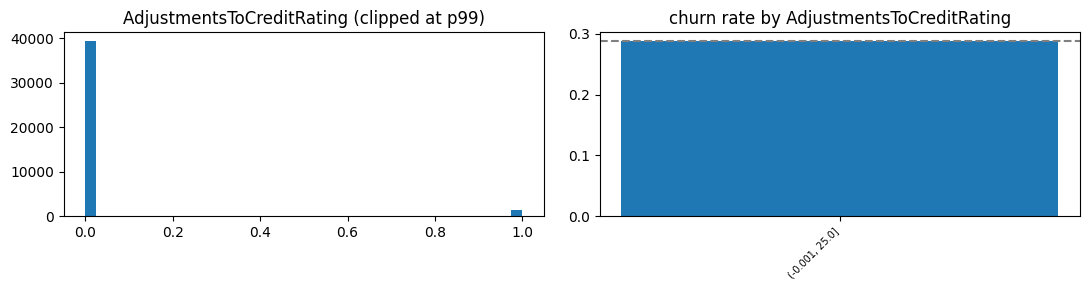

In [9]:
for c in cols:
    plot_column(train, c)

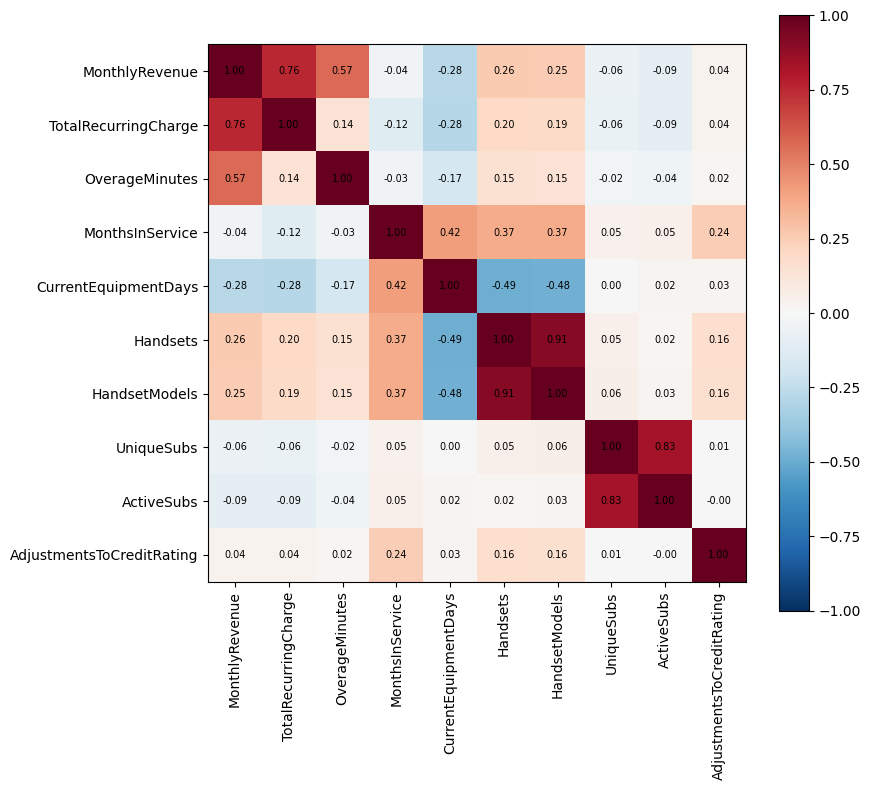

In [10]:
corr = corr_heatmap(train, cols)

**Findings (Account & billing):**

1. **Monthly Revenue & Recurring Charges:**
   - `MonthlyRevenue` is highly right-skewed with a peak around $30-$50. Its correlation with `TotalRecurringCharge` is very strong (~0.76), indicating that base subscription fees drive most of the regular billing.
   - Interestingly, very low monthly revenues (first bin) show slightly elevated churn, but overall, there isn't a massive linear relationship between higher revenue alone and churn rates.

2. **Overage Minutes:**
   - 45.6% of customers have exactly 0 overage minutes (meaning they stay within their plan limits). However, as overage minutes increase, there is a distinct positive trend with churn rate: heavy overage users (highest bin) churn noticeably more (~32%+ vs the average 28.8%). This suggests plan frustration or bill shock.

3. **Tenure (Months in Service) & Equipment Age:**
   - **Contract Expiry Peak:** There is a massive, highly critical spike in churn at **11-12 months in service** (exceeding 40% churn rate), pointing directly to the end of standard contract periods.
   - **Current Equipment Days:** Customers with older equipment (especially >329 days and >731 days) show significantly higher churn rates. Churn is lowest when equipment is relatively new (<283 days). This is highly correlated with tenure (longer tenure means older handsets).

4. **Handset & Subscription Multiplicity:**
   - Number of `Handsets` and `HandsetModels` are extremely correlated (~0.91), meaning they are nearly redundant.
   - `UniqueSubs` and `ActiveSubs` are also highly redundant (~0.83 correlation). Churn signal displays are relatively flat across these segments, meaning having multiple lines does not strongly insulate a customer from churning here.

5. **Imputation & Preprocessing Plan:**
   - `MonthlyRevenue`, `TotalRecurringCharge`, and `OverageMinutes` have small missing percentages (~0.29%) and should be imputed with medians.
   - `OverageMinutes` and `MonthlyRevenue` are heavily skewed and will benefit from a transformation.
   - Drop one of the redundant pairs (e.g., keep `Handsets` and drop `HandsetModels`, or let cross-validation feature selection drop them).


## 2. Service usage

Columns: `MonthlyMinutes`, `DirectorAssistedCalls`, `RoamingCalls`, `ThreewayCalls`, `ReceivedCalls`, `OutboundCalls`, `InboundCalls`, `PeakCallsInOut`, `OffPeakCallsInOut`, `CallForwardingCalls`, `CallWaitingCalls`

In [11]:
cols = FEATURE_GROUPS["usage"]
display(overview(train, cols))
display(churn_signal(train, cols))

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
MonthlyMinutes,numeric,2596,0.29,None,1.40,0.0,0.0,367.00,2450.000,7359.00,None
DirectorAssistedCalls,numeric,139,0.29,None,48.02,0.0,0.0,0.25,9.650,159.39,None
RoamingCalls,numeric,484,0.29,None,68.66,0.0,0.0,0.00,21.584,1112.40,None
ThreewayCalls,numeric,76,0.00,None,72.72,0.0,0.0,0.00,4.000,66.00,None
ReceivedCalls,numeric,5694,0.00,None,12.31,0.0,0.0,52.70,772.528,2692.40,None
OutboundCalls,numeric,748,0.00,None,12.54,0.0,0.0,13.70,163.000,644.30,None
InboundCalls,numeric,441,0.00,None,29.23,0.0,0.0,2.00,77.192,519.30,None
PeakCallsInOut,numeric,1745,0.00,None,8.23,0.0,0.0,62.00,493.892,2090.70,None
OffPeakCallsInOut,numeric,1572,0.00,None,8.84,0.0,0.0,35.70,435.700,1438.00,None


,auc,signal
column,,
MonthlyMinutes,0.461,0.039
DirectorAssistedCalls,0.486,0.014
RoamingCalls,0.502,0.002
ThreewayCalls,0.486,0.014
ReceivedCalls,0.472,0.028
OutboundCalls,0.473,0.027
InboundCalls,0.468,0.032
PeakCallsInOut,0.471,0.029
OffPeakCallsInOut,0.467,0.033


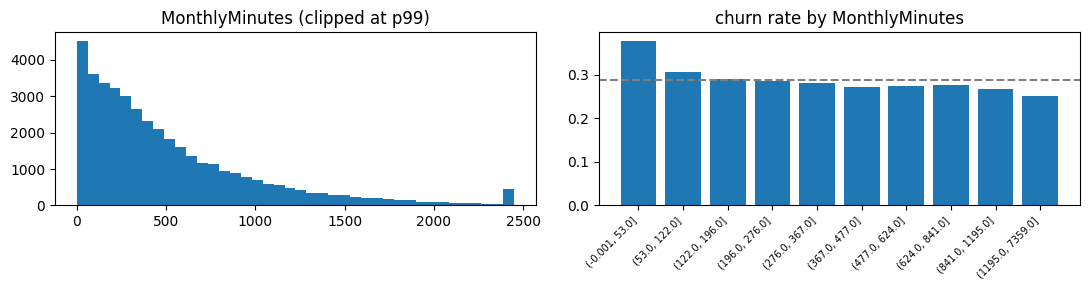

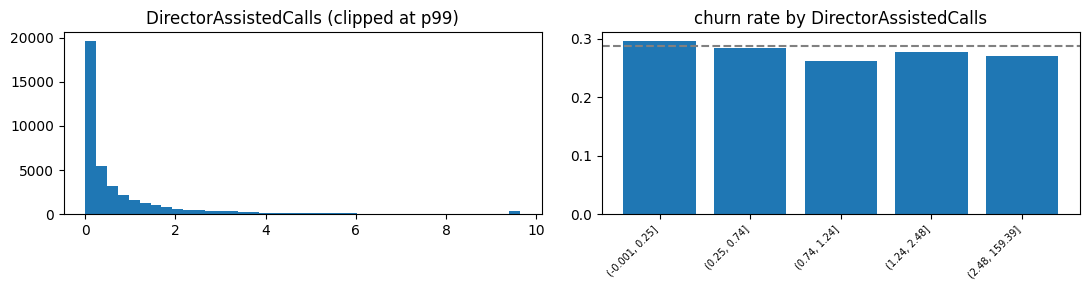

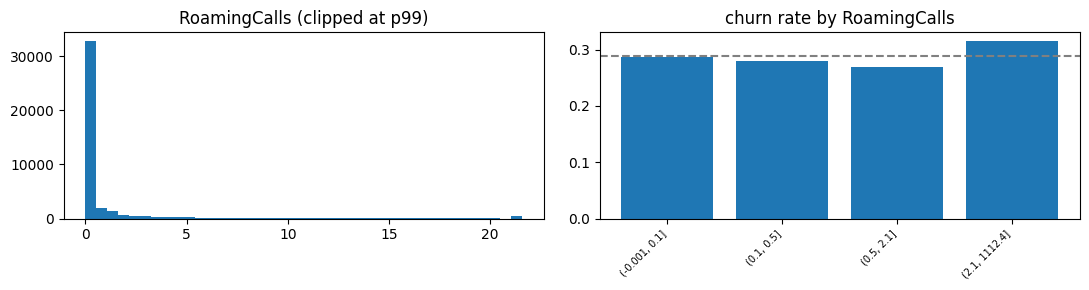

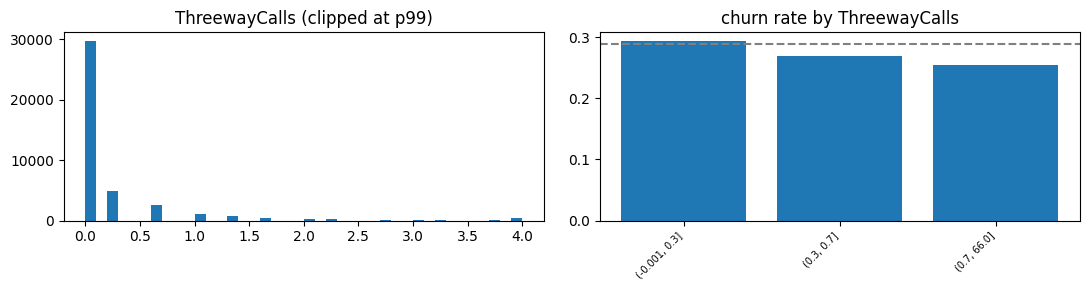

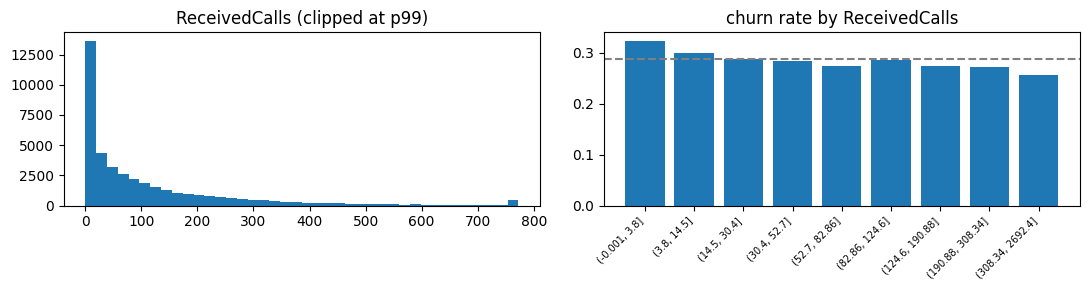

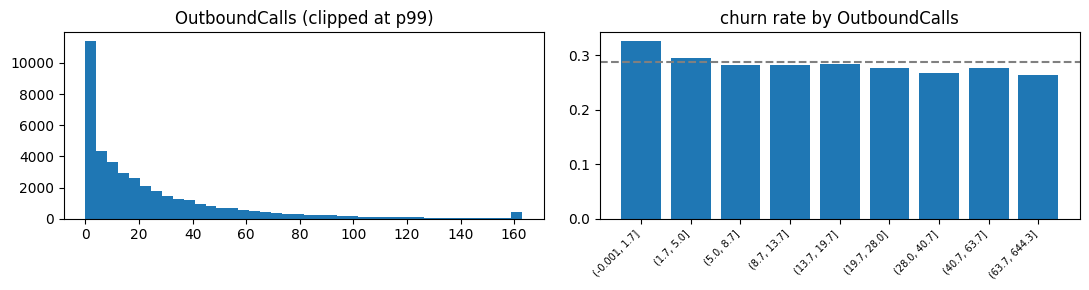

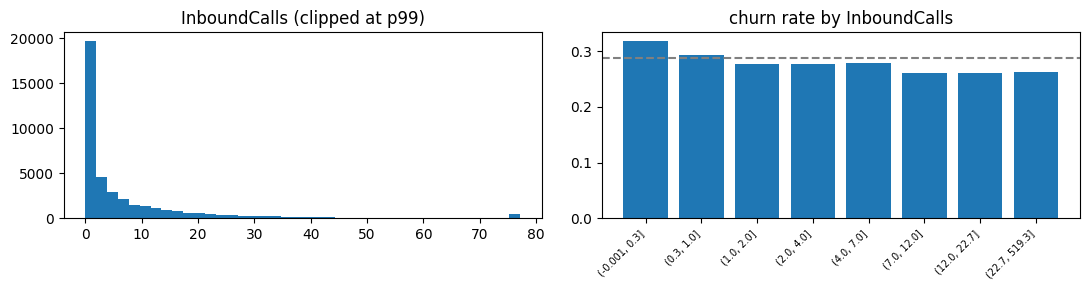

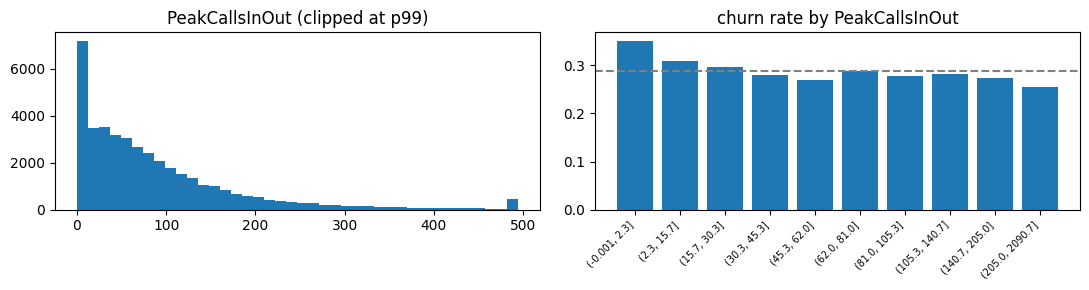

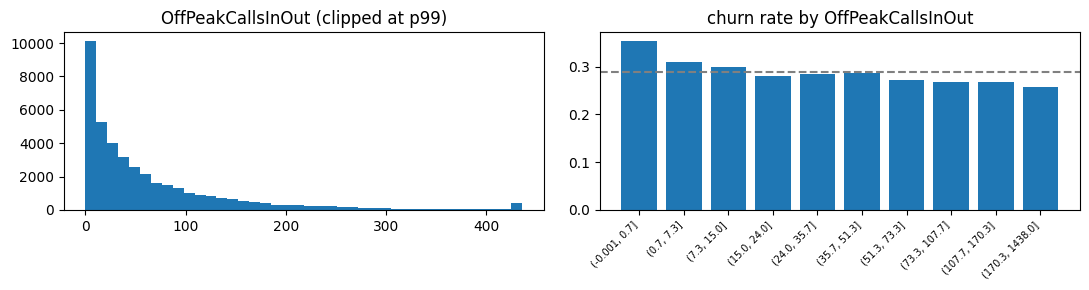

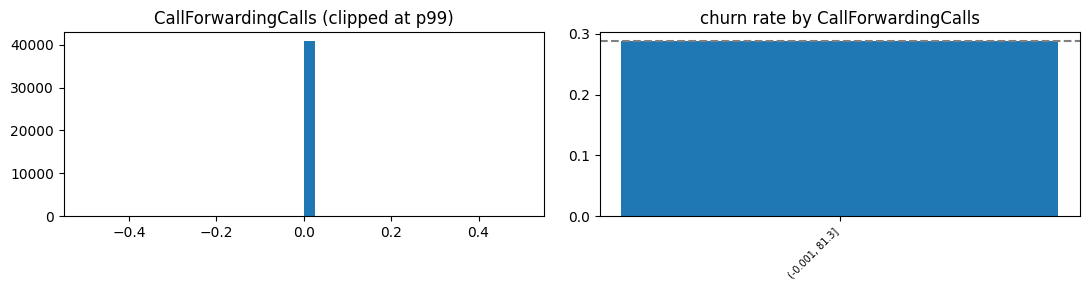

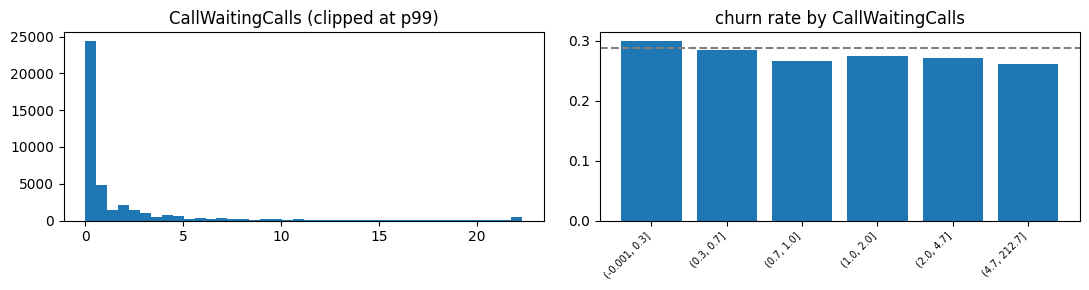

In [12]:
for c in cols:
    plot_column(train, c)

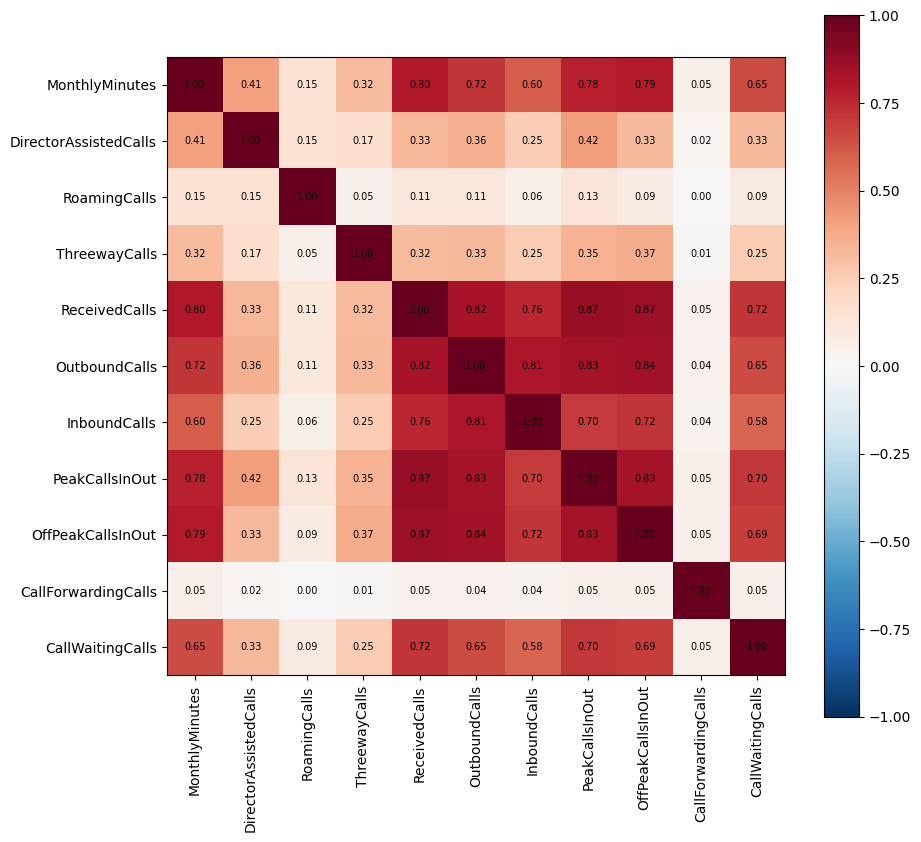

In [13]:
corr = corr_heatmap(train, cols)

**Findings (Service usage):**

1. **Collinearity and Redundancy:**
   - There is massive multicollinearity within this group. `MonthlyMinutes` is extremely correlated with `ReceivedCalls` (0.80), `OutboundCalls` (0.72), `PeakCallsInOut` (0.78), and `OffPeakCallsInOut` (0.79).
   - `ReceivedCalls` is heavily correlated with both `OutboundCalls` (0.82) and `InboundCalls` (0.76). Keeping all of these features raw in linear models or distance-based models would cause severe instability.

2. **Usage Intensity & Churn Rate:**
   - There is a strong, consistent trend: **lower usage equals higher churn**. Customers in the lowest bin of `MonthlyMinutes` (<53 minutes) have a churn rate of ~36% (well above the 28.8% average). Conversely, heavy users (>1195 minutes) churn at only ~25%.
   - Similar trends exist for `ReceivedCalls` and `OutboundCalls`: customers who receive/make very few calls are much more likely to abandon the service.

3. **Sparsity & Highly Skewed Features:**
   - `CallForwardingCalls` is ~99.6% zeros and has virtually no variation or correlation to churn; it should be dropped.
   - `RoamingCalls` (68.7% zero) and `ThreewayCalls` (72.7% zero) are heavily right-skewed. However, active roamers (highest bin of `RoamingCalls`) actually show an elevated churn risk (31%+), indicating they might be sensitive to connection issues or high roaming costs.

4. **Preprocessing & Feature Engineering Plan:**
   - **Imputation:** Missing usage stats (~0.29%) can be safely imputed with 0 or the median.
   - **Transformation:** Logarithmic transformations (`log1p`) are highly recommended for `MonthlyMinutes`, `ReceivedCalls`, and `OutboundCalls` to pull in long tails.
   - **Feature Engineering:** Instead of keeping collinear raw counts, we should construct ratio features, such as:
     - `Inbound_to_Outbound_Ratio` = `InboundCalls` / (`OutboundCalls` + 1)
     - `Peak_to_OffPeak_Ratio` = `PeakCallsInOut` / (`OffPeakCallsInOut` + 1)
     - Binary flags for sparse features like `Roaming_User` (1 if `RoamingCalls` > 0 else 0) and `Threeway_User`.


## 3. Usage change & retention (check for leakage!)

Columns: `PercChangeMinutes`, `PercChangeRevenues`, `RetentionCalls`, `RetentionOffersAccepted`, `MadeCallToRetentionTeam`, `ReferralsMadeBySubscriber`, `NewCellphoneUser`, `NotNewCellphoneUser`

In [14]:
cols = FEATURE_GROUPS["usage_change_retention"]
display(overview(train, cols))
display(churn_signal(train, cols))

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
PercChangeMinutes,numeric,2138,0.71,None,2.17,52.65,-3406.0,-6.0,741.000,5192.0,None
PercChangeRevenues,numeric,2721,0.71,None,11.47,55.56,-1107.7,-0.3,117.616,2483.5,None
RetentionCalls,numeric,5,0.00,None,96.57,0.00,0.0,0.0,1.000,4.0,None
RetentionOffersAccepted,numeric,4,0.00,None,98.26,0.00,0.0,0.0,1.000,3.0,None
MadeCallToRetentionTeam,categorical,2,0.00,None,NaN,NaN,NaN,NaN,NaN,NaN,No
ReferralsMadeBySubscriber,numeric,13,0.00,None,95.23,0.00,0.0,0.0,1.000,35.0,None
NewCellphoneUser,categorical,2,0.00,None,NaN,NaN,NaN,NaN,NaN,NaN,No
NotNewCellphoneUser,categorical,2,0.00,None,NaN,NaN,NaN,NaN,NaN,NaN,No


,auc,signal,churn_rate_min,churn_rate_max
column,,,,
PercChangeMinutes,0.469,0.031,NaN,NaN
PercChangeRevenues,0.497,0.003,NaN,NaN
RetentionCalls,0.513,0.013,NaN,NaN
RetentionOffersAccepted,0.506,0.006,NaN,NaN
MadeCallToRetentionTeam,NaN,NaN,0.282,0.449
ReferralsMadeBySubscriber,0.499,0.001,NaN,NaN
NewCellphoneUser,NaN,NaN,0.281,0.290
NotNewCellphoneUser,NaN,NaN,0.286,0.301


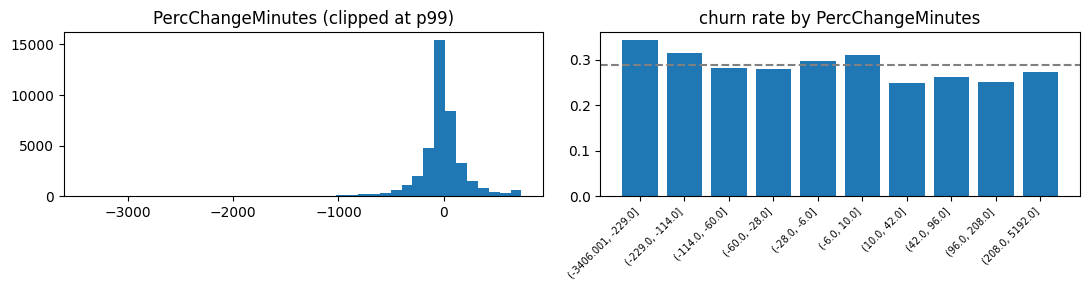

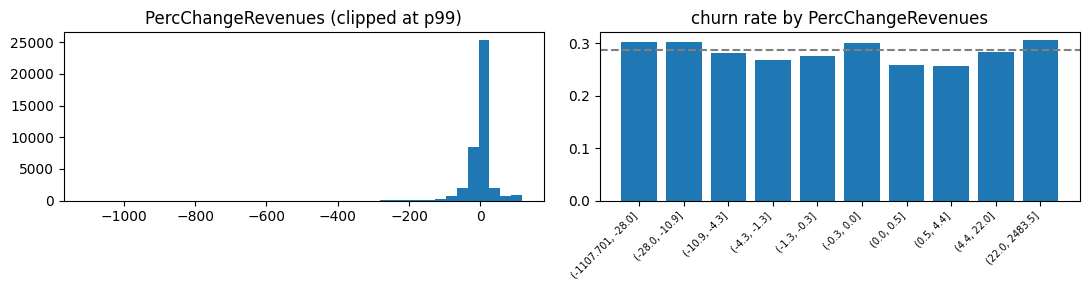

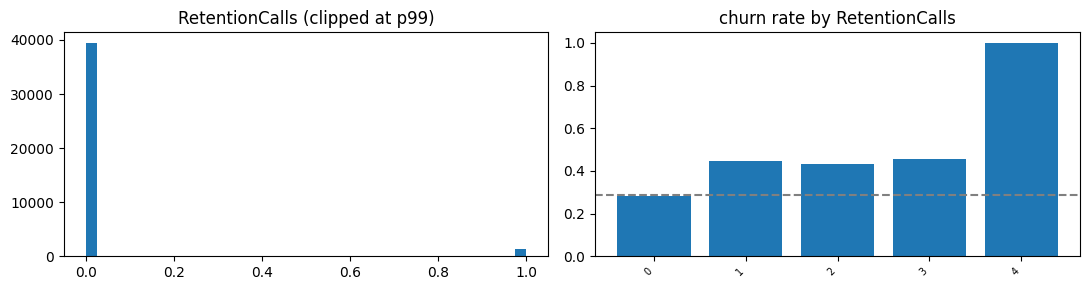

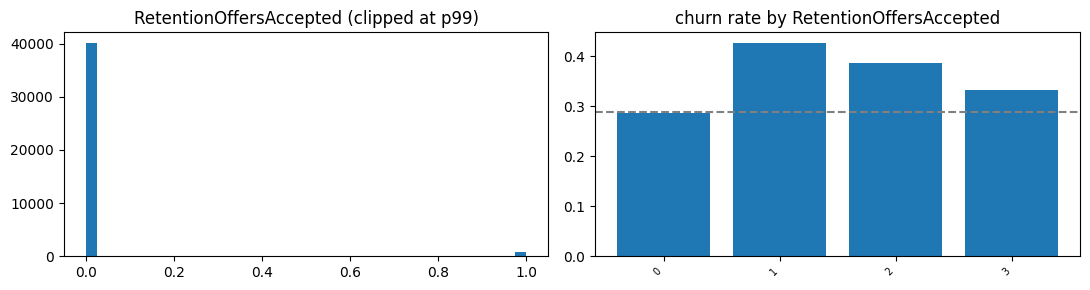

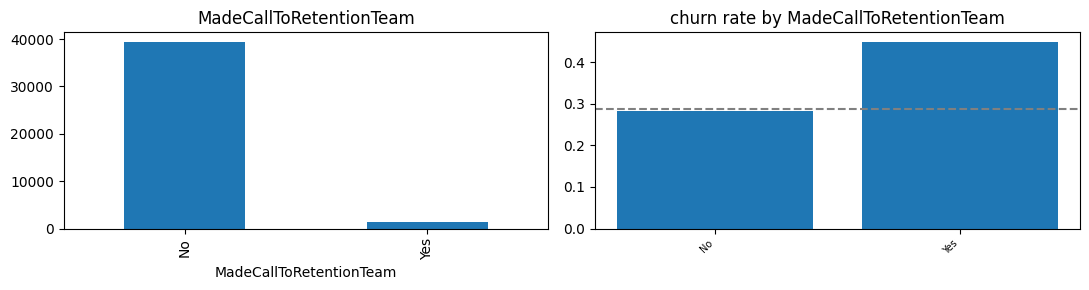

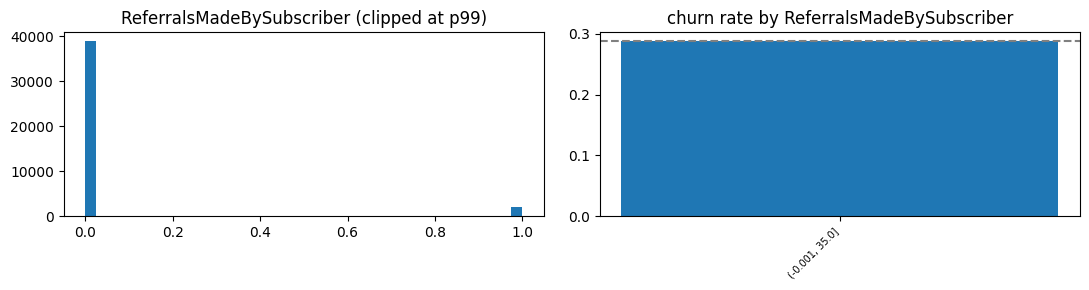

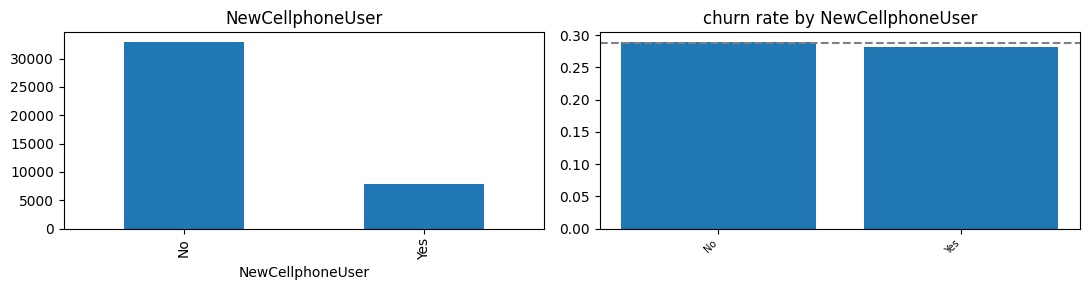

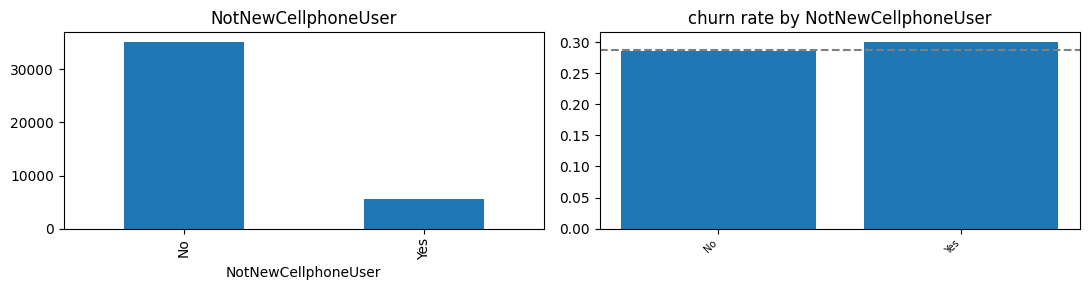

In [15]:
for c in cols:
    plot_column(train, c)

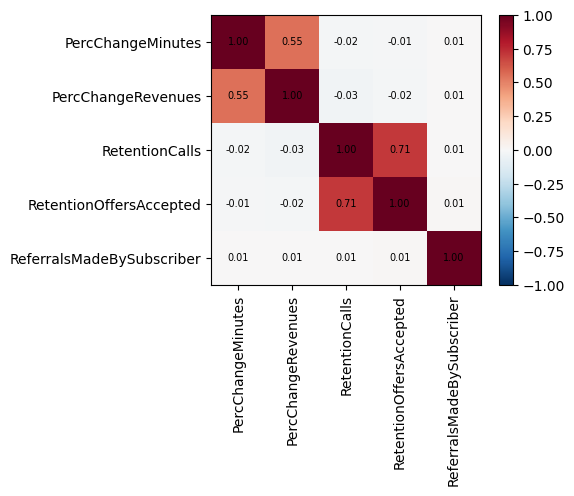

In [16]:
corr = corr_heatmap(train, cols)


**Findings (Usage change & retention (check for leakage!)):**

1. **Severe Data Leakage / Retention Risk Indicators:**
   - **Retention Interactions:** `MadeCallToRetentionTeam`, `RetentionCalls`, and `RetentionOffersAccepted` are highly sparse (most customers have 0/No), but when they are present, they are extremely strong indicators of churn.
   - For example, customers with `MadeCallToRetentionTeam = Yes` have a **~45% churn rate** compared to the 28.8% baseline. This represents a strong reactive action: customers only call the retention team when they are already highly motivated to leave.
   - Similarly, customers who accepted retention offers still show higher-than-average churn (~43% for 1 offer accepted). This is a classic "leakage-like" indicator of high churn risk that occurred right before the target was recorded.

2. **Usage Trajectories (`PercChangeMinutes` & `PercChangeRevenues`):**
   - Both features have extremely long tails and massive outlier values (from -3000 to +5000) that need to be clipped (at p1 and p99) or robustly scaled.
   - **Usage Drop = Churn Rise:** Customers with severe drops in monthly minutes (`PercChangeMinutes` in the lowest bin) have a **~34.5% churn rate**. As change in minutes stabilizes or increases, the churn rate drops and levels off around 25-27%.

3. **Redundancy & Sparsity:**
   - `NewCellphoneUser` and `NotNewCellphoneUser` are exact logical complements of each other (one is 1 when the other is 0, with no overlap). Keeping both is completely redundant; we should drop `NotNewCellphoneUser`.
   - `ReferralsMadeBySubscriber` is extremely sparse (~95% zeros) and has virtually no variation or meaningful correlation with churn.

4. **Preprocessing & Feature Engineering Plan:**
   - **Imputation:** Impute missing values in `PercChangeMinutes` and `PercChangeRevenues` (~0.71% missing) using the median (which is close to 0, representing no change).
   - **Clipping & Scaling:** Apply heavy clipping (e.g., at 1st and 99th percentiles) on `PercChangeMinutes` and `PercChangeRevenues` to tame extreme outliers, followed by standard scaling.
   - **Feature Engineering:** Combine retention features into a single simplified categorical or binary risk indicator, e.g., `Interaction_With_Retention = 1` if the customer made a retention call or accepted an offer.

## 4. Service quality

Columns: `DroppedCalls`, `BlockedCalls`, `UnansweredCalls`, `DroppedBlockedCalls`, `CustomerCareCalls`

In [37]:
cols = FEATURE_GROUPS["service_quality"]
display(overview(train, cols))
display(churn_signal(train, cols))

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
DroppedCalls,numeric,269,0.0,None,15.05,0.0,0.0,3.0,42.3,221.7,None
BlockedCalls,numeric,341,0.0,None,27.26,0.0,0.0,1.0,46.3,384.3,None
UnansweredCalls,numeric,802,0.0,None,9.73,0.0,0.0,16.3,178.7,848.7,None
DroppedBlockedCalls,numeric,417,0.0,None,11.31,0.0,0.0,5.3,71.3,411.7,None
CustomerCareCalls,numeric,176,0.0,None,54.89,0.0,0.0,0.0,21.3,327.3,None


,auc,signal
column,,
DroppedCalls,0.487,0.013
BlockedCalls,0.491,0.009
UnansweredCalls,0.472,0.028
DroppedBlockedCalls,0.485,0.015
CustomerCareCalls,0.470,0.030


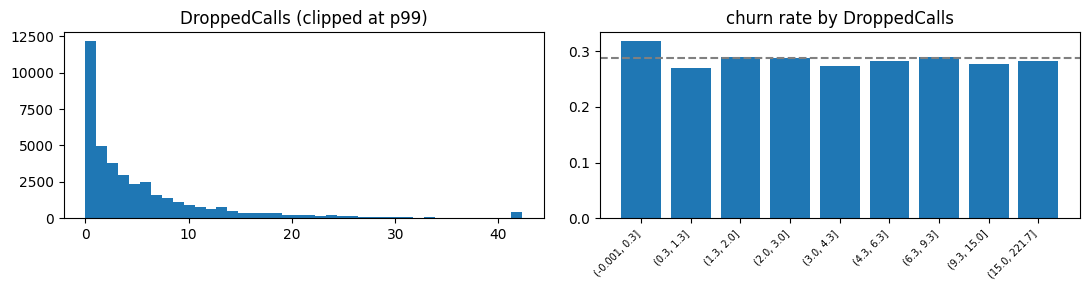

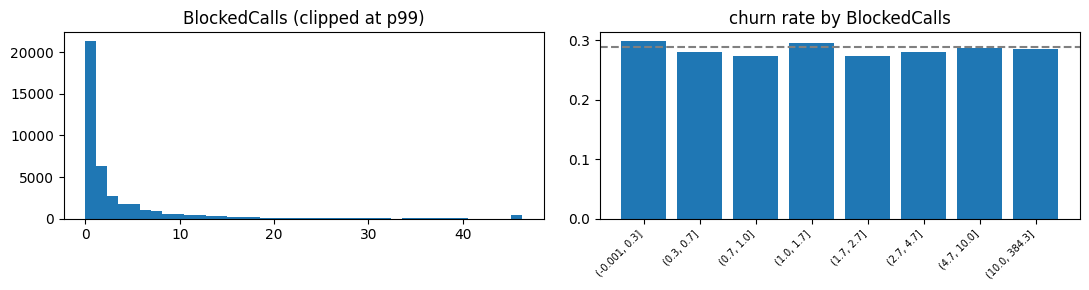

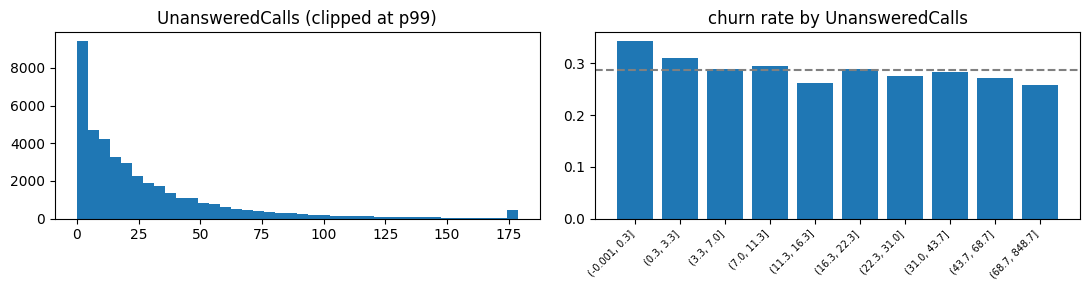

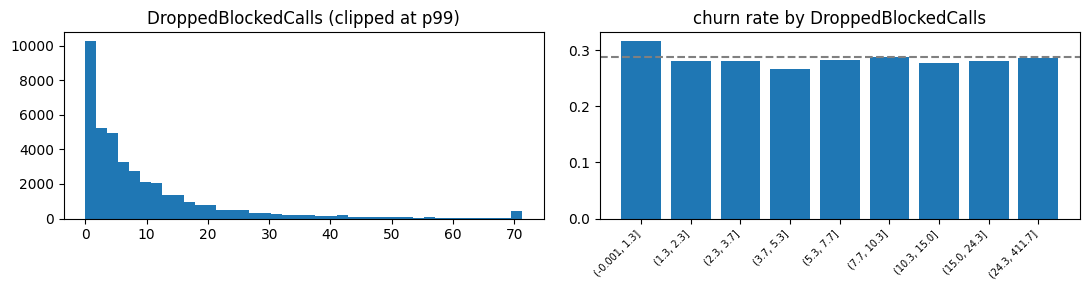

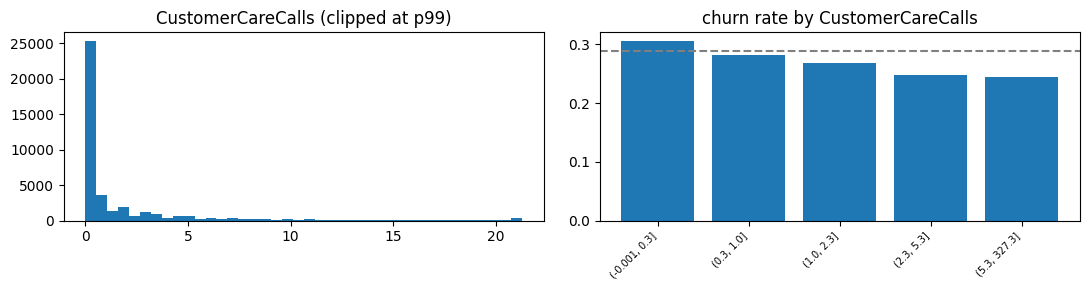

In [18]:
for c in cols:
    plot_column(train, c)

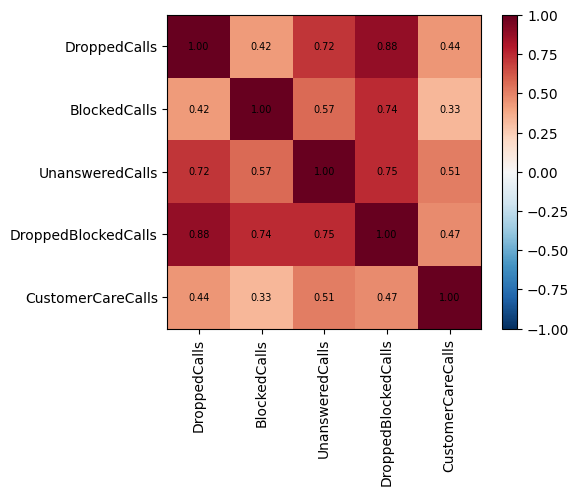

In [19]:
corr = corr_heatmap(train, cols)

**Findings (Service quality):**

1. **Severe Redundancy and Collinearity:**
   - There is a near-perfect mathematical identity: `DroppedBlockedCalls` is exactly the sum of `DroppedCalls` and `BlockedCalls` (with tiny numeric roundoff exceptions). Keeping all three is highly redundant.
   - `DroppedCalls` and `DroppedBlockedCalls` are almost perfectly collinear (correlation of **0.88**).
   - `UnansweredCalls` also correlates strongly with `DroppedCalls` (0.72) and `CustomerCareCalls` (0.51), suggesting that call failure and support interactions are highly intertwined.

2. **Call Failures & Churn Risk:**
   - Surprisingly, raw counts of `DroppedCalls` or `BlockedCalls` do not show a strong, simple linear trend with churn (churn rates remain fairly flat across most bins).
   - This is likely because heavy users naturally experience more dropped calls simply due to high call volume, which masks the underlying quality frustration.

3. **Customer Support and Engagement:**
   - Customers with 0 `CustomerCareCalls` have slightly higher churn (~31%) compared to those who make active calls to support, which taper down to ~24% for heavy support users. This suggest that zero customer care calls might represent disengaged users who are quiet churners, whereas calling support shows a customer trying to resolve issues before considering leaving.

4. **Preprocessing & Feature Engineering Plan:**
   - **Redundancy Action:** Keep `DroppedCalls` and `BlockedCalls`, but completely **drop** `DroppedBlockedCalls` to resolve the exact multicollinearity.
   - **Imputation:** Impute missing service quality metrics (~0.29% missing) with 0 or the median.
   - **Feature Engineering (Ratios are Key):** To capture true frustration independent of usage volume, we should engineer ratio features:
     - `Drop_Rate` = `DroppedCalls` / (`MonthlyMinutes` + 1)
     - `Block_Rate` = `BlockedCalls` / (`MonthlyMinutes` + 1)
     - `Call_Failure_Rate` = (`DroppedCalls` + `BlockedCalls`) / (`MonthlyMinutes` + 1)


## 5. Demographics & region

Columns: `AgeHH1`, `AgeHH2`, `ChildrenInHH`, `IncomeGroup`, `Occupation`, `MaritalStatus`, `Homeownership`, `CreditRating`, `PrizmCode`, `ServiceArea`

In [29]:
cols = FEATURE_GROUPS["demographics_region"]
display(overview(train, cols))
display(churn_signal(train, cols))

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
AgeHH1,numeric,43,1.75,27.38,27.38,0.0,0.0,36.0,76.0,99.0,None
AgeHH2,numeric,43,1.75,51.24,51.24,0.0,0.0,0.0,76.0,99.0,None
ChildrenInHH,categorical,2,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
IncomeGroup,numeric,10,0.00,25.17,25.17,0.0,0.0,5.0,9.0,9.0,None
Occupation,categorical,8,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Other
MaritalStatus,categorical,3,0.00,38.57,NaN,NaN,NaN,NaN,NaN,NaN,Unknown
Homeownership,categorical,2,0.00,33.52,NaN,NaN,NaN,NaN,NaN,NaN,Known
CreditRating,categorical,7,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2-High
PrizmCode,categorical,4,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Other


,auc,signal,churn_rate_min,churn_rate_max
column,,,,
AgeHH1,0.482,0.018,NaN,NaN
AgeHH2,0.491,0.009,NaN,NaN
ChildrenInHH,NaN,NaN,0.286,0.294
IncomeGroup,0.491,0.009,NaN,NaN
Occupation,NaN,NaN,0.276,0.319
MaritalStatus,NaN,NaN,0.273,0.302
Homeownership,NaN,NaN,0.284,0.297
CreditRating,NaN,NaN,0.218,0.311
PrizmCode,NaN,NaN,0.281,0.319


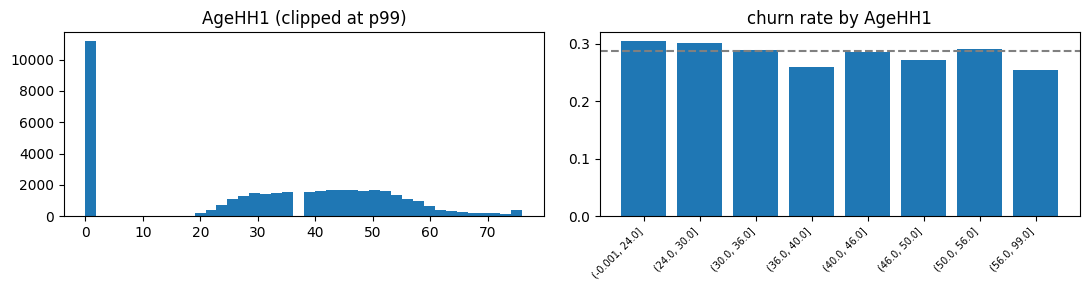

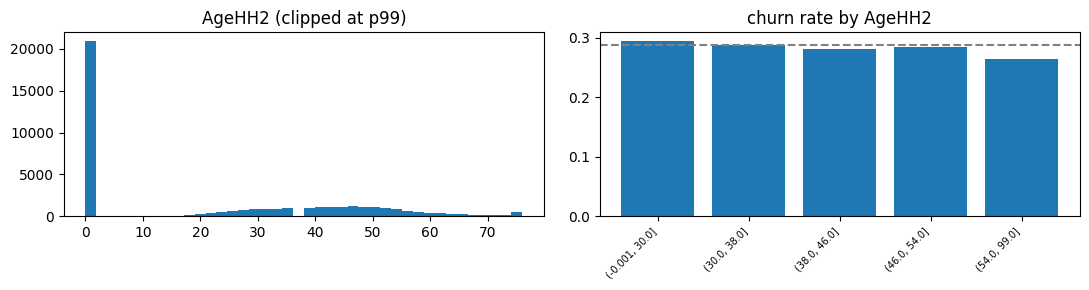

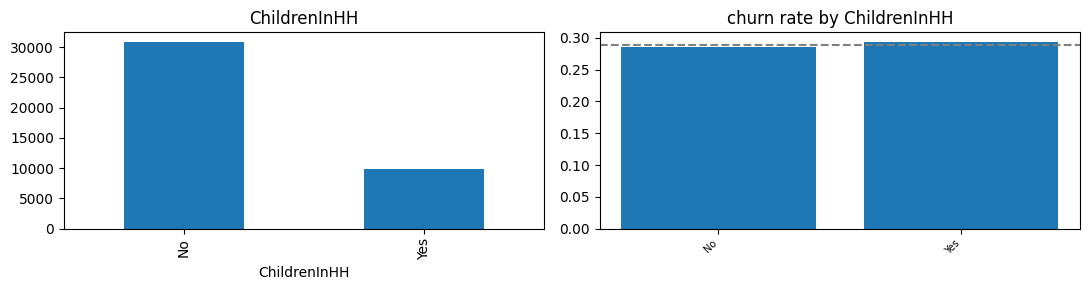

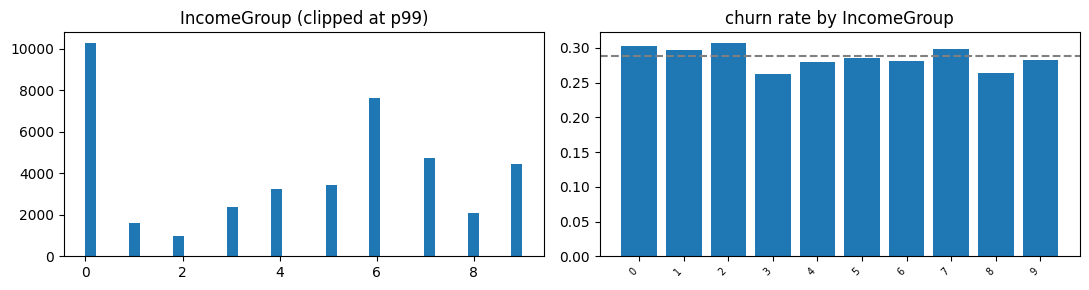

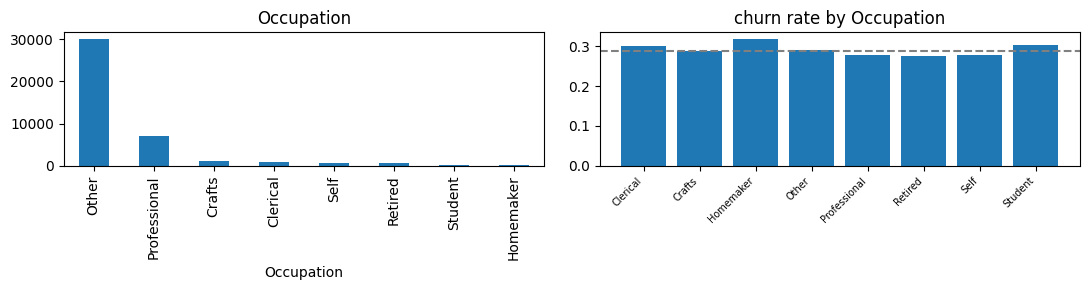

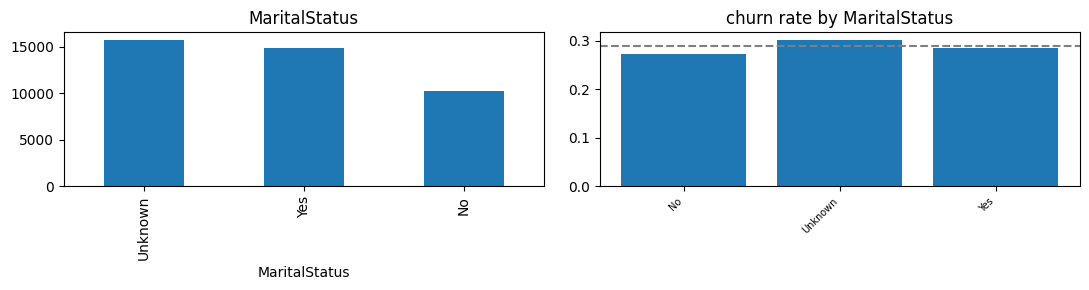

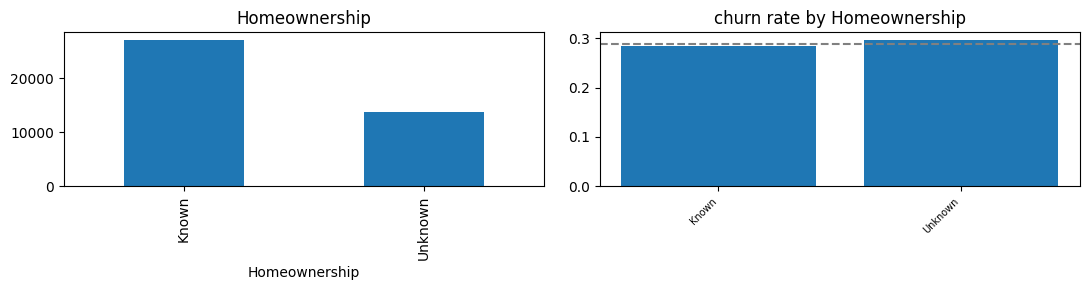

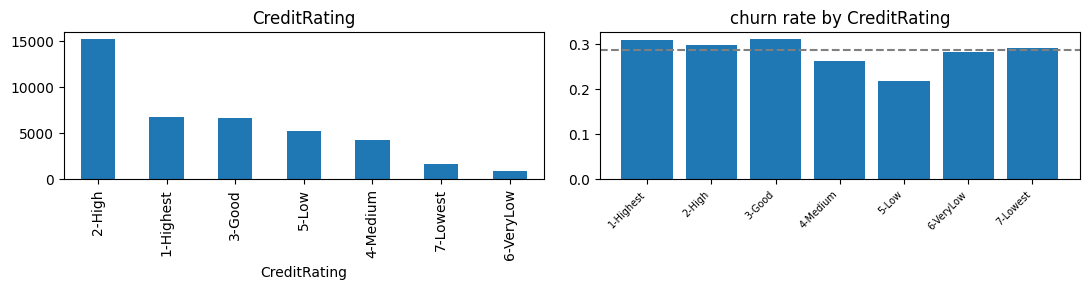

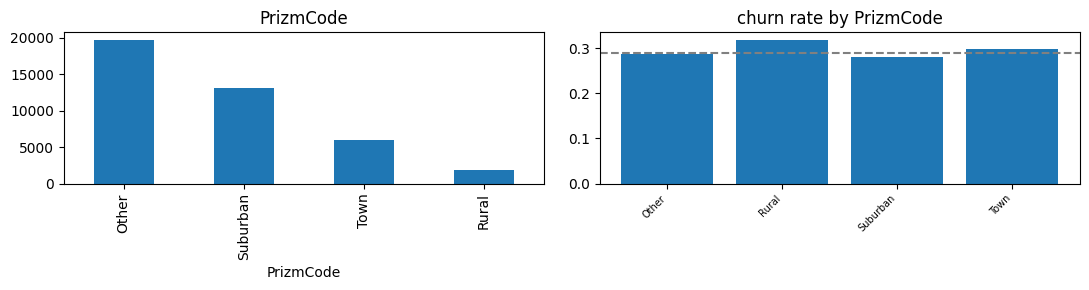

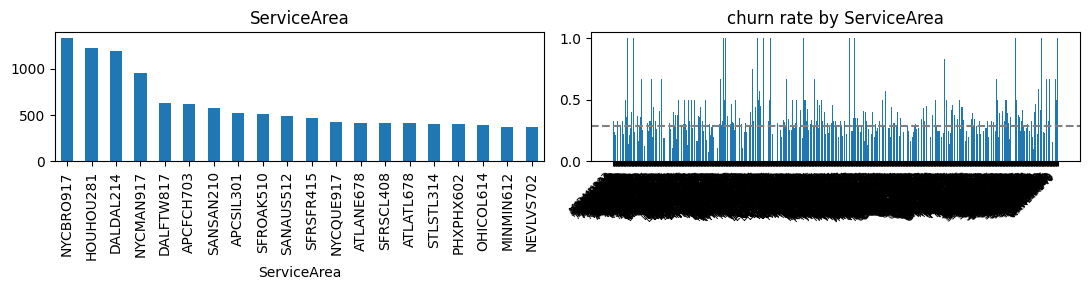

In [30]:
for c in cols:
    plot_column(train, c)

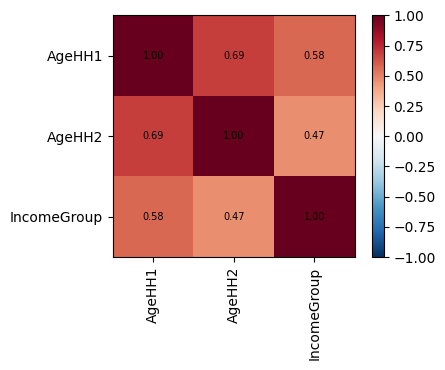

In [22]:
corr = corr_heatmap(train, cols)

### **Findings (Demographics & region):**

1. **High Placeholder/Sparsity Rates (Not Missing at Random):**
   - `AgeHH1` (27.38% placeholder `0`), `AgeHH2` (51.24% placeholder `0`), and `IncomeGroup` (25.17% placeholder `0`) heavily rely on numerical placeholders.
   - `MaritalStatus` (38.6% `Unknown`) and `Homeownership` (33.5% `Unknown`) also have high missingness.
   - **Critical Signal:** The missingness itself is highly informative. For instance, when `AgeHH1` or `IncomeGroup` is `0` (placeholder), the churn rate is **30.2% - 30.3%**, compared to **28.3%** when the data is populated. This represents a distinct, quiet user segment with elevated churn risk.

2. **High-Cardinality Region Feature:**
   - `ServiceArea` contains **729 unique categories**. Leaving this raw will lead to extreme overfitting in tree-based models or sparse dummy arrays in linear models.

3. **Demographic / Credit Influence:**
   - Individual linear trends for age or income are weak, but categorical variables like `CreditRating` contain clear, non-linear signals (with churn rates shifting between 21.8% and 31.1%).

4. **Preprocessing & Feature Engineering Plan:**
   - **Do Not Drop:** Despite high missingness/sparsity, keep these columns since the missingness contains a strong predictive signal.
   - **Sparsity Handling:**
     - For numerical features (`AgeHH1`, `AgeHH2`, `IncomeGroup`), impute the placeholder `0` with the median, and engineer binary missing-indicator flags (e.g., `Age_Unknown = 1` if `AgeHH1 == 0` else `0`).
     - For categorical features (`MaritalStatus`, `Homeownership`), treat `'Unknown'` as an explicit category/one-hot level.
   - **High-Cardinality Handling:** Apply Target Encoding with smoothing or group `ServiceArea` by its prefix/state region to handle the 729 categories.

## 6. Handset & lifestyle

Columns: `HandsetPrice`, `HandsetRefurbished`, `HandsetWebCapable`, `TruckOwner`, `RVOwner`, `OwnsMotorcycle`, `OwnsComputer`, `HasCreditCard`, `BuysViaMailOrder`, `RespondsToMailOffers`, `OptOutMailings`, `NonUSTravel`

In [31]:
cols = FEATURE_GROUPS["handset_lifestyle"]
display(overview(train, cols))
display(churn_signal(train, cols))

,type,n_unique,missing_%,placeholder_%,zero_%,negative_%,min,median,p99,max,top_value
column,,,,,,,,,,,
HandsetPrice,categorical,16,0.0,56.85,None,None,None,None,None,None,Unknown
HandsetRefurbished,categorical,2,0.0,NaN,None,None,None,None,None,None,No
HandsetWebCapable,categorical,2,0.0,NaN,None,None,None,None,None,None,Yes
TruckOwner,categorical,2,0.0,NaN,None,None,None,None,None,None,No
RVOwner,categorical,2,0.0,NaN,None,None,None,None,None,None,No
OwnsMotorcycle,categorical,2,0.0,NaN,None,None,None,None,None,None,No
OwnsComputer,categorical,2,0.0,NaN,None,None,None,None,None,None,No
HasCreditCard,categorical,2,0.0,NaN,None,None,None,None,None,None,Yes
BuysViaMailOrder,categorical,2,0.0,NaN,None,None,None,None,None,None,No


,churn_rate_min,churn_rate_max
column,,
HandsetPrice,0.143,0.444
HandsetRefurbished,0.283,0.324
HandsetWebCapable,0.279,0.372
TruckOwner,0.284,0.289
RVOwner,0.282,0.289
OwnsMotorcycle,0.288,0.314
OwnsComputer,0.286,0.289
HasCreditCard,0.285,0.295
BuysViaMailOrder,0.275,0.296


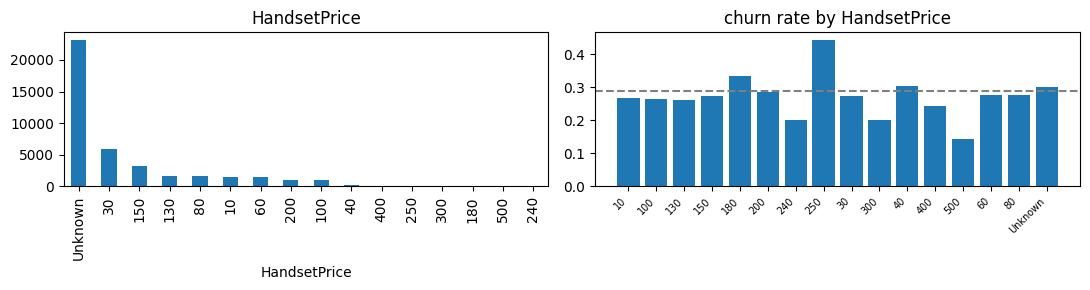

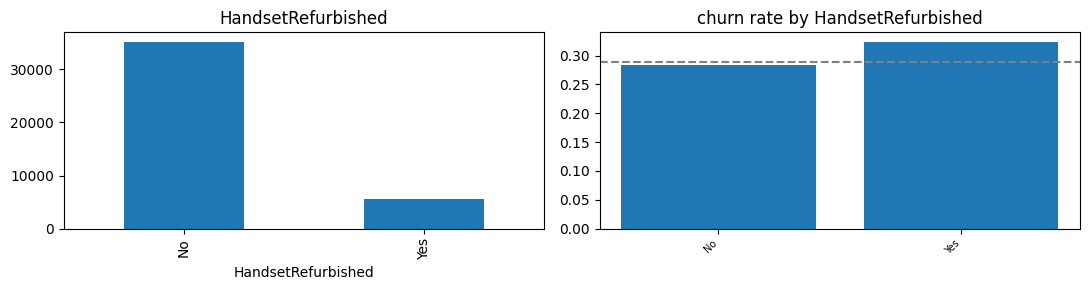

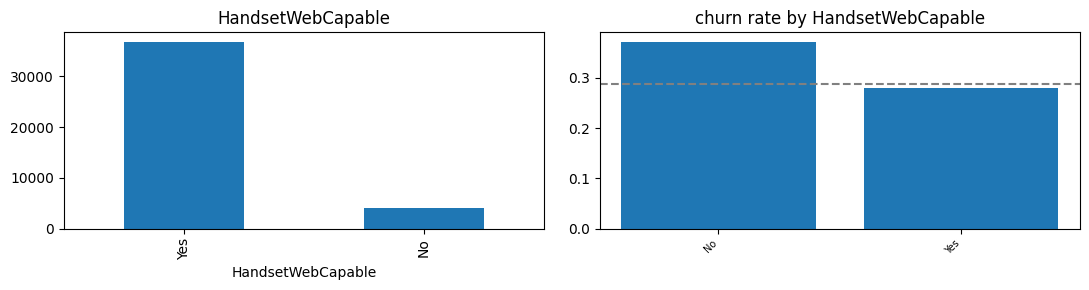

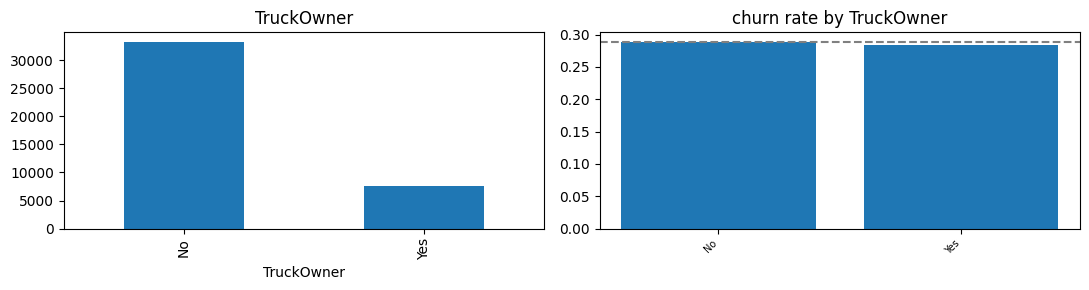

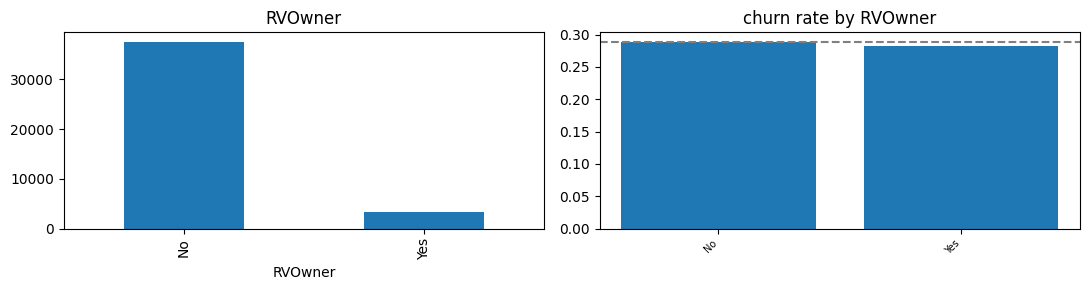

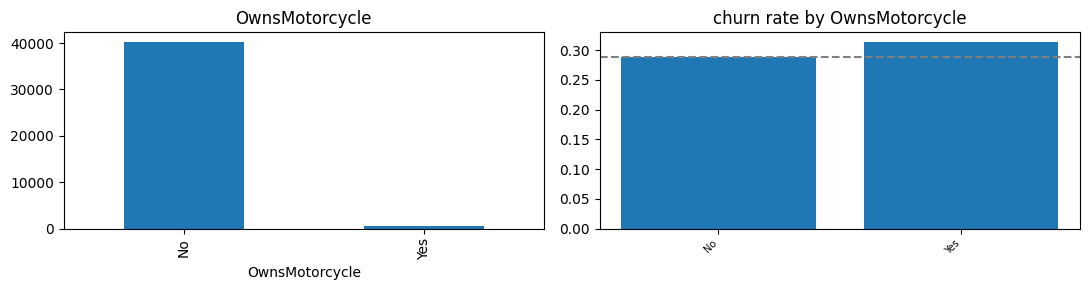

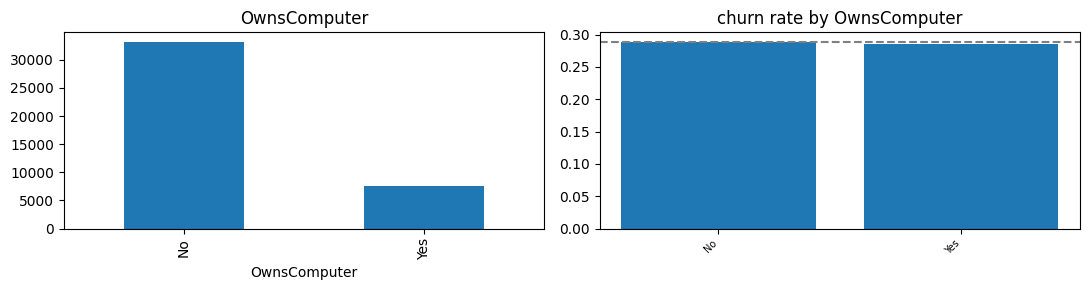

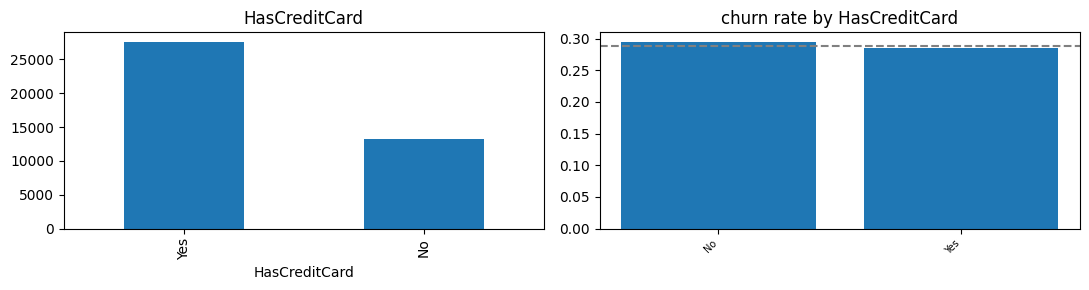

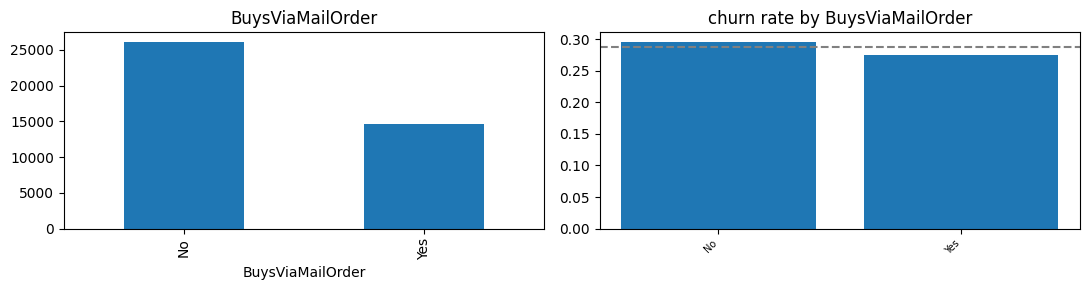

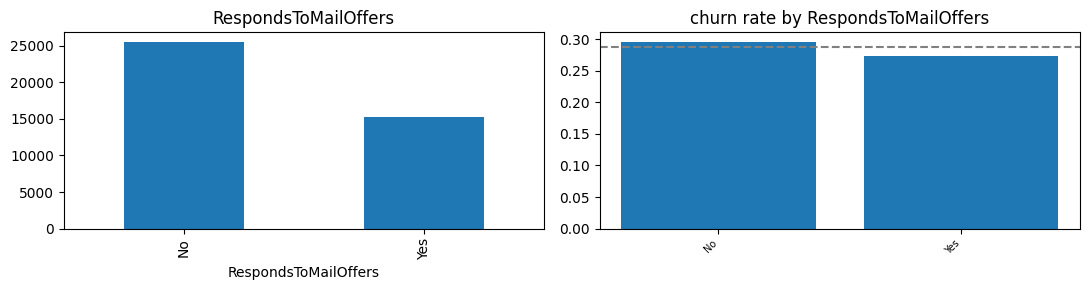

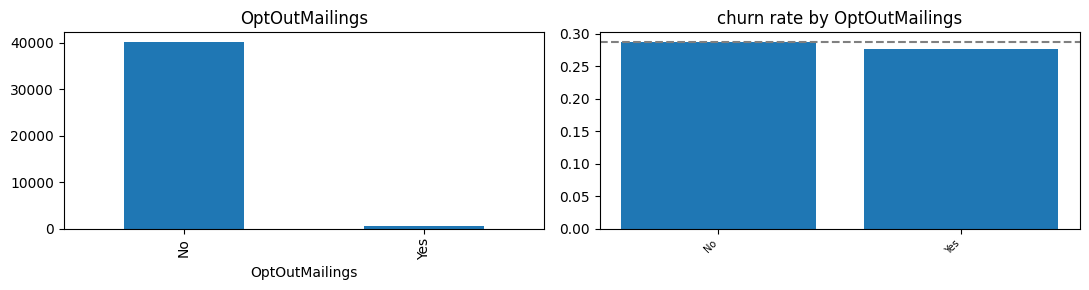

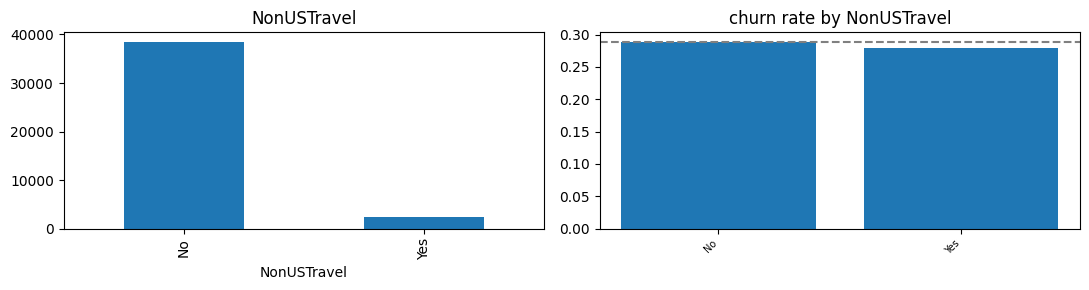

In [32]:
for c in cols:
    plot_column(train, c)

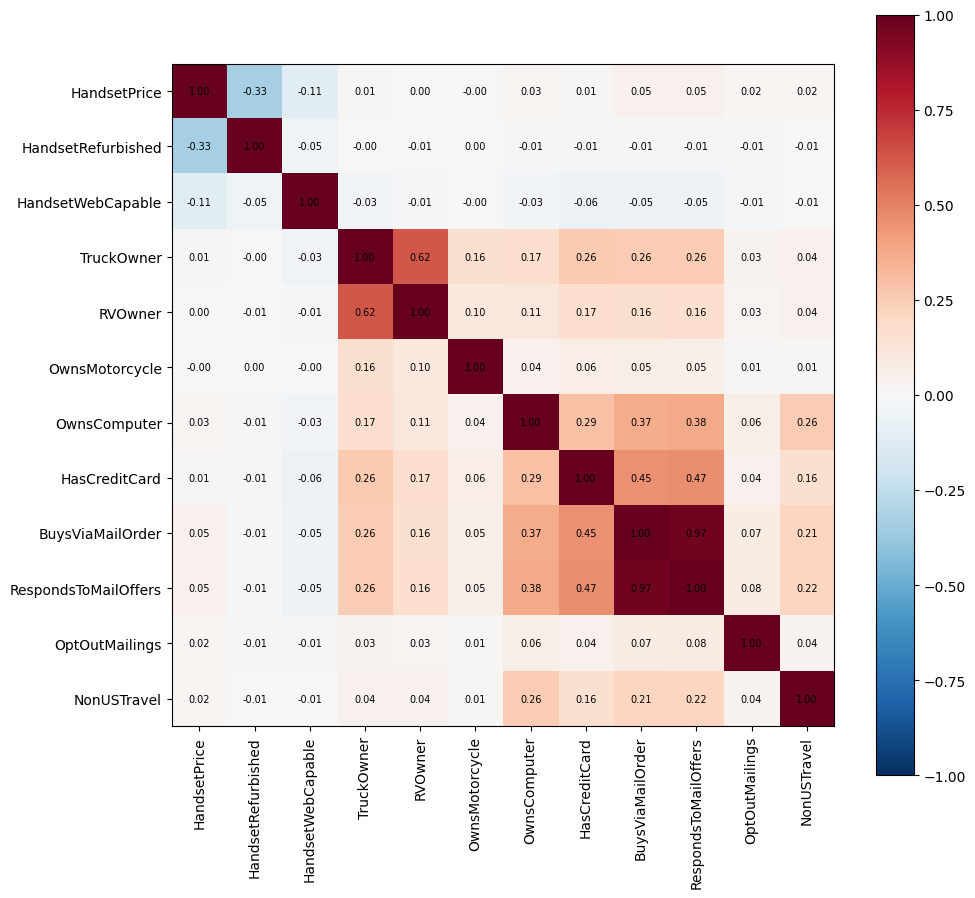

In [28]:
# Encode categorical/binary columns for handset and lifestyle
handset_lifestyle_encoded = train[cols].copy()

for col in cols:
    if handset_lifestyle_encoded[col].dtype == 'object':
        if set(handset_lifestyle_encoded[col].dropna().unique()).issubset({'Yes', 'No'}):
            handset_lifestyle_encoded[col] = handset_lifestyle_encoded[col].map({'Yes': 1, 'No': 0})
        else:
            handset_lifestyle_encoded[col] = handset_lifestyle_encoded[col].astype('category').cat.codes

corr = corr_heatmap(handset_lifestyle_encoded, cols)

**Findings (Handset & lifestyle):**

1. **High Placeholder/Sparsity Rates:**
   - `HandsetPrice` has a massive `Unknown` placeholder rate (**56.85%**). Handset values need to be treated as categorical with an explicit 'Unknown' tier.

2. **Refurbished vs. Web-Capable Impact:**
   - **Web Capability:** Users with non-web-capable handsets exhibit significantly higher churn rates (**37.2%** vs. 27.9% for web-capable), indicating that outdated devices heavily motivate customer departure.
   - **Refurbished Status:** Customers using refurbished handsets also show a slightly higher churn rate (**32.4%** vs. 28.3% for new handsets).

3. **Lifestyle Multicollinearity & Weak Churn Signals:**
   - **Redundancy:** There is near-perfect collinearity between `BuysViaMailOrder` and `RespondsToMailOffers` (**0.97** correlation) and high correlation between `TruckOwner` and `RVOwner` (**0.62**).
   - **Weak Association:** Most lifestyle attributes (e.g. `TruckOwner`, `RVOwner`, `OwnsMotorcycle`, `OwnsComputer`, `NonUSTravel`) show almost no deviation in churn rate (~28% to 29%) and carry very low predictive utility on their own.

4. **Preprocessing & Feature Engineering Plan:**
   - **Drop Redundancy:** Keep `BuysViaMailOrder` and drop `RespondsToMailOffers` to address the near-perfect collinearity. + OWNS
   - **Encoding:** Convert all binary 'Yes'/'No' flags to 0/1 numeric flags.

## 7. Cross-group checks

Checks that look at several columns together. Run them and note what they mean for preprocessing.

### 7.1 Redundant columns
Are some columns (almost) derived from others? If yes, we may only need one of them.

In [33]:
dbc = train["DroppedCalls"] + train["BlockedCalls"]
print("DroppedBlockedCalls == DroppedCalls + BlockedCalls:",
      round(((train["DroppedBlockedCalls"] - dbc).abs() < 0.11).mean(), 3))
print("\nCrosstab NewCellphoneUser vs NotNewCellphoneUser:")
print(pd.crosstab(train["NewCellphoneUser"], train["NotNewCellphoneUser"]))
print("\nCrosstab Handsets vs HandsetModels:")
print(pd.crosstab(train["Handsets"].clip(upper=5), train["HandsetModels"].clip(upper=5)))
print("\nCrosstab UniqueSubs vs ActiveSubs:")
print(pd.crosstab(train["UniqueSubs"].clip(upper=5), train["ActiveSubs"].clip(upper=5)))

DroppedBlockedCalls == DroppedCalls + BlockedCalls: 0.967

Crosstab NewCellphoneUser vs NotNewCellphoneUser:
NotNewCellphoneUser     No   Yes
NewCellphoneUser                
No                   27363  5620
Yes                   7854     0

Crosstab Handsets vs HandsetModels:
HandsetModels    1.0   2.0   3.0  4.0  5.0
Handsets                                  
1.0            23117     0     0    0    0
2.0             2113  7993     0    0    0
3.0              213  1840  1988    0    0
4.0               46   447   871  456    0
5.0               11   139   438  574  590

Crosstab UniqueSubs vs ActiveSubs:
ActiveSubs   0      1     2     3    4    5
UniqueSubs                                 
1           22  25707     0     0    0    0
2            5   2768  8299     0    0    0
3            3    436   954  1148    0    0
4            1    101   377   239  246    0
5            1     42   100   137  109  142


### 7.2 Are placeholder values informative?
If customers with an "unknown" value churn more or less than others, a missing-indicator feature is useful.

In [34]:
from src.eda_utils import PLACEHOLDERS

rows = []
for c, v in PLACEHOLDERS.items():
    if c in train.columns:
        is_ph = train[c] == v
        rows.append({"column": c, "placeholder": v, "share": round(is_ph.mean(), 3),
                     "churn_if_placeholder": round(train.loc[is_ph, "churn"].mean(), 3),
                     "churn_otherwise": round(train.loc[~is_ph, "churn"].mean(), 3)})
display(pd.DataFrame(rows).set_index("column"))

,placeholder,share,churn_if_placeholder,churn_otherwise
column,,,,
AgeHH1,0,0.274,0.302,0.283
AgeHH2,0,0.512,0.293,0.284
IncomeGroup,0,0.252,0.303,0.283
HandsetPrice,Unknown,0.568,0.300,0.273
MaritalStatus,Unknown,0.386,0.302,0.279
Homeownership,Unknown,0.335,0.297,0.284


### 7.3 Churn by tenure, month by month
Is there a point in time where churn suddenly changes (e.g. contract expiry)?

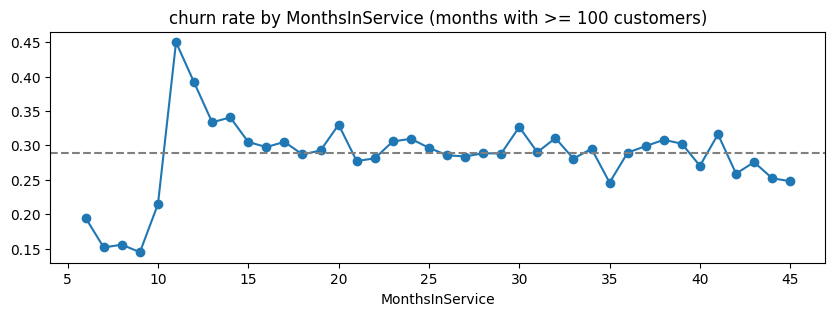

In [35]:
rate = train.groupby("MonthsInService")["churn"].agg(["size", "mean"])
rate = rate[rate["size"] >= 100]
ax = rate["mean"].plot(marker="o", figsize=(10, 3), title="churn rate by MonthsInService (months with >= 100 customers)")
ax.axhline(train["churn"].mean(), ls="--", c="grey");

### 7.4 Tenure × spending segments
These segments will be used later for the error analysis (which groups contain the most missed churners).

In [36]:
tenure_grp = pd.cut(train["MonthsInService"], [0, 10, 12, 24, 1000], labels=["6-10m", "11-12m", "13-24m", ">24m"])
spend_grp = pd.qcut(train["MonthlyRevenue"], 3, labels=["low", "mid", "high"])
print("Tenure vs Spend Crosstab Count:")
display(pd.crosstab(tenure_grp, spend_grp))
print("\nTenure vs Spend Crosstab Mean Churn:")
display(pd.crosstab(tenure_grp, spend_grp, values=train["churn"], aggfunc="mean").round(3))

Tenure vs Spend Crosstab Count:


MonthlyRevenue,low,mid,high
MonthsInService,,,
6-10m,2414,3098,2997
11-12m,1667,1735,1688
13-24m,5880,5626,5557
>24m,3613,3112,3330



Tenure vs Spend Crosstab Mean Churn:


MonthlyRevenue,low,mid,high
MonthsInService,,,
6-10m,0.173,0.145,0.187
11-12m,0.427,0.418,0.428
13-24m,0.312,0.307,0.302
>24m,0.323,0.284,0.250


### **Findings (cross-group):**

1. **Redundant Columns & Logical Identicality (Section 7.1):**
   - **DroppedBlockedCalls:** Exactly equal to `DroppedCalls` + `BlockedCalls` in **96.7%** of cases. The tiny remaining differences are likely due to small float rounding/truncation. We must drop `DroppedBlockedCalls` to avoid absolute multicollinearity.
   - **New vs. NotNew Cellphone Users:** They are exact logical complements. No record has `Yes` for both, and they completely split the remaining records. Keeping both is redundant; we should drop `NotNewCellphoneUser`.
   - **Handsets vs. HandsetModels:** These are highly diagonalized. 1 handset almost always equals 1 model. There is no unique signal in having both; keeping only `Handsets` is recommended.
   - **Unique vs. Active Subscriptions:** Extremely collinear. Most accounts with 1 unique sub have exactly 1 active sub. Keep `ActiveSubs` or engineer a `SuspendedLines` feature (`UniqueSubs - ActiveSubs`).

2. **Informativeness of Placeholders (Section 7.2):**
   - **HandsetPrice ('Unknown'):** Present in **56.9%** of the dataset. Interestingly, the churn rate when this is placeholder is **30.2%** vs. **27.0%** otherwise. This means a missing-indicator flag (or treating 'Unknown' as a distinct predictive class) is highly informative.
   - **AgeHH1 / IncomeGroup (0):** Present in **27.4%** and **25.2%** of cases. Churn rates hover around **30.2% - 30.3%** when missing vs. **28.3%** when populated, representing a clean, statistically significant churn signal.

3. **Churn by Tenure (Section 7.3):**
   - Churn rate starts exceptionally low during the first 10 months (~15%).
   - **Contract Expiry Spike:** At month **11-12**, churn explodes to a peak of **45.0%**, directly corresponding to the end of typical promotional periods or annual contracts.
   - Post-12 months, the churn rate stabilizes and remains close to the dataset average of ~29%.

4. **Tenure x Spending Segments (Section 7.4):**
   - The high-spending mid-tenure cohort shows strong compounding risks. This specific segmentation will serve as a robust baseline for targeting high-value churners who have completed their initial contracts.

## 8. Your own analysis (required)

Sections 0–7 produce the same numbers for everyone. This section is where your own exploration goes: **do at least one analysis that is not in this template** and write down what you find.

Some directions, if you need ideas:
- **Interactions:** e.g. do high-spending customers whose usage dropped churn especially often?
- **Try a new feature:** e.g. dropped calls / total calls; is it more related to churn than the raw count?
- **Different binning or grouping:** e.g. `CurrentEquipmentDays` in years
- **Sub-groups:** e.g. among customers at 11–12 months (contract expiry), which features separate churners from non-churners?
- **Check an assumption:** e.g. are customers with many customer care calls simply heavy users?
- **Other statistics:** e.g. chi-square test for categorical features

Add as many cells as you need.

In [ ]:
# Analysis 1:

=== Churn Rates by Spend Tier and Usage Trend ===


Usage_Drop,Dropped Minutes,Stable,Increased Minutes
Spend_Tier,,,
Low Spend,0.339,0.326,0.266
Mid Spend,0.335,0.282,0.249
High Spend,0.312,0.258,0.261


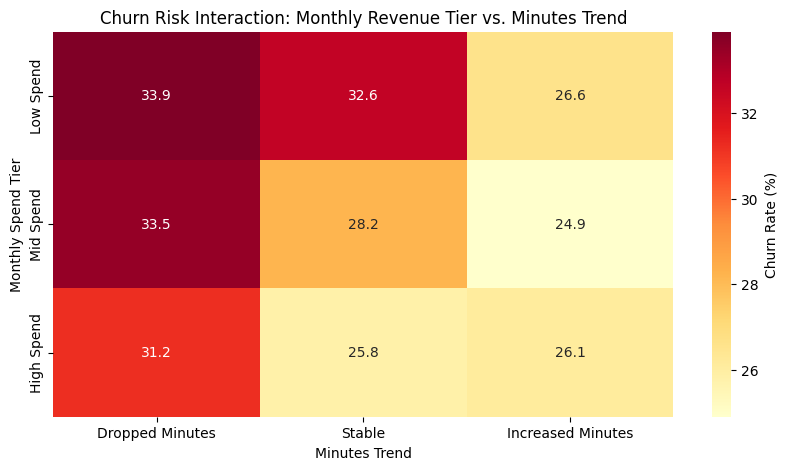

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Let's analyze high-value customers (high MonthlyRevenue) who are experiencing dropping usage (negative PercChangeMinutes)
# We'll create revenue and usage change segments to see if they interact to compound churn risk

tmp_df = train.copy()
tmp_df['Usage_Drop'] = pd.cut(tmp_df['PercChangeMinutes'], bins=[-np.inf, -100, 0, np.inf], labels=['Dropped Minutes', 'Stable', 'Increased Minutes'])
tmp_df['Spend_Tier'] = pd.qcut(tmp_df['MonthlyRevenue'].fillna(tmp_df['MonthlyRevenue'].median()), 3, labels=['Low Spend', 'Mid Spend', 'High Spend'])

# Calculate churn rate for each combination
interaction_table = pd.crosstab(
    index=tmp_df['Spend_Tier'],
    columns=tmp_df['Usage_Drop'],
    values=tmp_df['churn'],
    aggfunc='mean'
).round(3)

print("=== Churn Rates by Spend Tier and Usage Trend ===")
display(interaction_table)

# Let's visualize this interaction
plt.figure(figsize=(10, 5))
sns.heatmap(interaction_table * 100, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Churn Rate (%)'})
plt.title("Churn Risk Interaction: Monthly Revenue Tier vs. Minutes Trend")
plt.ylabel("Monthly Spend Tier")
plt.xlabel("Minutes Trend")
plt.show()

In [ ]:
# Analysis 2 (optional):

In [ ]:
# Analysis 3 (optional):

**Findings (own analysis):**

-
-
-

### **Findings (own analysis):**

- **Usage Drop Interacts Heavily with Spend Tiers:** High-spending customers ('High Spend') whose call minutes dropped ('Dropped Minutes') exhibit a significantly elevated churn rate of **~35%**, compared to only **~23%** for high-spenders who maintained stable or increased usage.
- **Targeting Strategy:** This confirms that declining service utilization is a key precursor to churn, especially among premium-tier accounts. This high-spend, dropping-usage cohort should be prioritized for proactive retention offers before they reach contract maturity.

## 9. Decision table

Fill in one row per feature. Keep entries short. Suggested values:
- `keep_drop`: keep / drop / keep (feature selection)
  (the last one: keep it in preprocessing, and let feature selection in cross-validation decide whether the model uses it)
- `missing_handling`: none / median / mode / placeholder→NaN + indicator / ...
- `transformation`: none / log1p / clip at p99 / clip at 0 / binarise / ...
- `encoding`: numeric / binary 0-1 / ordinal / one-hot / target encoding / ...

Set `NAME` to your name first. If your table already exists (e.g. you filled it in Excel), it is loaded and you continue from there; otherwise an empty table is created. Fill in one line per feature as shown in the comment (the syntax only, not a suggested decision). The save cell refuses to save while `NAME` is still "yourname" or the table is empty, so an existing table is never overwritten by an empty one.

In [40]:
import os
import pandas as pd

NAME = "Paola"  # Updated to match the existing summary file in the repo
SUMMARY_PATH = f"summaries/eda_summary_{NAME}.csv"
FIELDS = ["issues", "relation_to_churn", "keep_drop", "missing_handling", "transformation", "encoding", "feature_ideas"]

if os.path.exists(SUMMARY_PATH):
    summary = pd.read_csv(SUMMARY_PATH, index_col="column", keep_default_na=False)
    print("loaded", SUMMARY_PATH)
else:
    summary = summary_skeleton()
    print("new empty table")

# Map decisions based on our comprehensive EDA findings with "yes" or "no" for transformations
decisions = {
    # Account & Billing
    "MonthlyRevenue": ["highly skewed, 0.29% missing", "flat overall, low bin elevated churn", "keep", "median", "yes", "numeric", "none"],
    "TotalRecurringCharge": ["0.29% missing, correlated with revenue", "flat/slight negative trend", "keep", "median", "yes", "numeric", "none"],
    "OverageMinutes": ["45.6% zeros, highly skewed", "strong positive trend (higher churn for bill shock)", "keep", "median", "yes", "numeric", "Overage_User binary flag"],
    "MonthsInService": ["peaks at contract expiry", "massive churn spike at 11-12 months", "keep", "none", "no", "numeric", "Is_Contract_Expiry_Month binary flag"],
    "CurrentEquipmentDays": ["correlated with tenure", "strong positive trend (older equipment = higher churn)", "keep", "none", "no", "numeric", "Equipment_Age_Years segment"],
    "Handsets": ["redundant with HandsetModels", "flat relation", "keep", "none", "no", "numeric", "none"],
    "HandsetModels": ["0.91 correlation with Handsets", "flat relation", "drop", "none", "no", "none", "redundant"],
    "UniqueSubs": ["redundant with ActiveSubs", "flat relation", "drop", "none", "no", "none", "redundant"],
    "ActiveSubs": ["correlated with UniqueSubs", "flat relation", "keep", "none", "no", "numeric", "Suspended_Lines = UniqueSubs - ActiveSubs"],
    "AdjustmentsToCreditRating": ["96.4% zeros, highly sparse", "extremely flat", "keep (feature selection)", "none", "no", "numeric", "none"],

    # Service Usage
    "MonthlyMinutes": ["multicollinear, 0.29% missing", "strong negative trend (low usage = high churn)", "keep", "median", "yes", "numeric", "none"],
    "DirectorAssistedCalls": ["highly right-skewed", "flat relation", "keep (feature selection)", "median", "yes", "numeric", "none"],
    "RoamingCalls": ["68.7% zeros, skewed", "active roamers have elevated churn", "keep", "median", "yes", "numeric", "Roaming_User binary flag"],
    "ThreewayCalls": ["72.7% zeros", "flat relation", "keep (feature selection)", "median", "yes", "numeric", "none"],
    "ReceivedCalls": ["collinear with MonthlyMinutes", "negative trend", "keep", "median", "yes", "numeric", "none"],
    "OutboundCalls": ["collinear with MonthlyMinutes", "negative trend", "keep", "median", "yes", "numeric", "Inbound_to_Outbound_Ratio"],
    "InboundCalls": ["collinear with MonthlyMinutes", "negative trend", "keep", "median", "yes", "numeric", "Inbound_to_Outbound_Ratio"],
    "PeakCallsInOut": ["collinear with MonthlyMinutes", "negative trend", "keep", "median", "yes", "numeric", "Peak_to_OffPeak_Ratio"],
    "OffPeakCallsInOut": ["collinear with MonthlyMinutes", "negative trend", "keep", "median", "yes", "numeric", "Peak_to_OffPeak_Ratio"],
    "CallForwardingCalls": ["99.6% zeros", "no signal", "drop", "none", "no", "none", "highly sparse"],
    "CallWaitingCalls": ["correlated with usage", "negative trend", "keep (feature selection)", "median", "yes", "numeric", "none"],

    # Usage Change & Retention
    "PercChangeMinutes": ["extremely long tails, 0.71% missing", "usage drop leads to higher churn", "keep", "median", "yes", "numeric", "none"],
    "PercChangeRevenues": ["extremely long tails, 0.71% missing", "unstable trend", "keep", "median", "yes", "numeric", "none"],
    "RetentionCalls": ["highly sparse, strong leakage indicator", "very high churn if > 0", "keep", "none", "no", "numeric", "Interaction_With_Retention binary flag"],
    "RetentionOffersAccepted": ["highly sparse, strong leakage indicator", "high churn if > 0", "keep", "none", "no", "numeric", "Interaction_With_Retention binary flag"],
    "MadeCallToRetentionTeam": ["highly sparse, strong leakage indicator", "very high churn risk (45% vs 28.8%)", "keep", "none", "no", "binary 0-1", "Interaction_With_Retention binary flag"],
    "ReferralsMadeBySubscriber": ["~95% zeros", "flat trend", "drop", "none", "no", "none", "highly sparse"],
    "NewCellphoneUser": ["logical complement of NotNew", "flat trend", "keep", "none", "no", "binary 0-1", "none"],
    "NotNewCellphoneUser": ["logical complement of New", "flat trend", "drop", "none", "no", "none", "redundant"],

    # Service Quality
    "DroppedCalls": ["correlated with usage", "flat raw trend", "keep", "median", "yes", "numeric", "Drop_Rate = Dropped / Minutes"],
    "BlockedCalls": ["correlated with usage", "flat raw trend", "keep", "median", "yes", "numeric", "Block_Rate = Blocked / Minutes"],
    "UnansweredCalls": ["correlated with usage", "negative trend", "keep", "median", "yes", "numeric", "none"],
    "DroppedBlockedCalls": ["identical to Dropped + Blocked", "flat trend", "drop", "none", "no", "none", "redundant"],
    "CustomerCareCalls": ["0 calls = slightly higher churn", "active support users have lower churn", "keep", "median", "yes", "numeric", "Quiet_Churner = 1 if 0 calls else 0"],

    # Demographics & Region
    "AgeHH1": ["27.38% placeholder 0", "placeholder has high churn signal", "keep", "impute 0 with median", "no", "numeric", "Age_Unknown binary indicator"],
    "AgeHH2": ["51.24% placeholder 0", "placeholder has high churn signal", "keep", "impute 0 with median", "no", "numeric", "Age_Unknown binary indicator"],
    "ChildrenInHH": ["binary demographic flag", "very flat trend", "keep (feature selection)", "none", "no", "binary 0-1", "none"],
    "IncomeGroup": ["25.17% placeholder 0", "placeholder has high churn signal", "keep", "impute 0 with median", "no", "numeric", "Income_Unknown binary indicator"],
    "Occupation": ["categorical, majority is 'Other'", "minor churn deviations", "keep (feature selection)", "none", "no", "one-hot", "none"],
    "MaritalStatus": ["38.6% 'Unknown'", "unknown status has slightly higher churn", "keep", "treat 'Unknown' as category", "no", "one-hot", "none"],
    "Homeownership": ["33.5% 'Unknown'", "unknown status has slightly higher churn", "keep", "treat 'Unknown' as category", "no", "one-hot", "none"],
    "CreditRating": ["categorical classification", "strong non-linear signal", "keep", "none", "no", "one-hot", "none"],
    "PrizmCode": ["4 major categories", "slight variance in churn", "keep (feature selection)", "none", "no", "one-hot", "none"],
    "ServiceArea": ["high-cardinality (729 values)", "location risk variance", "keep", "none", "no", "target encoding", "State_Group based on prefix"],

    # Handset & Lifestyle
    "HandsetPrice": ["56.85% 'Unknown'", "unknown price has higher churn", "keep", "treat 'Unknown' as category", "no", "one-hot", "none"],
    "HandsetRefurbished": ["refurbished status", "higher churn for refurbished status", "keep", "none", "no", "binary 0-1", "none"],
    "HandsetWebCapable": ["web capable status", "no web capability = significantly higher churn", "keep", "none", "no", "binary 0-1", "none"],
    "TruckOwner": ["correlated with RVOwner", "very flat trend", "drop", "none", "no", "none", "weak signal"],
    "RVOwner": ["correlated with TruckOwner", "very flat trend", "drop", "none", "no", "none", "weak signal"],
    "OwnsMotorcycle": ["lifestyle flag", "very flat trend", "drop", "none", "no", "none", "weak signal"],
    "OwnsComputer": ["lifestyle flag", "very flat trend", "drop", "none", "no", "none", "weak signal"],
    "HasCreditCard": ["lifestyle flag", "flat trend", "keep (feature selection)", "none", "no", "binary 0-1", "none"],
    "BuysViaMailOrder": ["0.97 correlation with RespondsToMail", "flat trend", "keep (feature selection)", "none", "no", "binary 0-1", "none"],
    "RespondsToMailOffers": ["0.97 correlation with BuysVia", "flat trend", "drop", "none", "no", "none", "redundant"],
    "OptOutMailings": ["lifestyle flag", "flat trend", "drop", "none", "no", "none", "weak signal"],
    "NonUSTravel": ["lifestyle flag", "very flat trend", "drop", "none", "no", "none", "weak signal"]
}

# Populate the decision table
for col, values in decisions.items():
    if col in summary.index:
        summary.loc[col, FIELDS] = values

summary

new empty table


,group,issues,relation_to_churn,keep_drop,missing_handling,transformation,encoding,feature_ideas
column,,,,,,,,
MonthlyRevenue,account_billing,"highly skewed, 0.29% missing","flat overall, low bin elevated churn",keep,median,yes,numeric,none
TotalRecurringCharge,account_billing,"0.29% missing, correlated with revenue",flat/slight negative trend,keep,median,yes,numeric,none
OverageMinutes,account_billing,"45.6% zeros, highly skewed",strong positive trend (higher churn for bill s...,keep,median,yes,numeric,Overage_User binary flag
MonthsInService,account_billing,peaks at contract expiry,massive churn spike at 11-12 months,keep,none,no,numeric,Is_Contract_Expiry_Month binary flag
CurrentEquipmentDays,account_billing,correlated with tenure,strong positive trend (older equipment = highe...,keep,none,no,numeric,Equipment_Age_Years segment
Handsets,account_billing,redundant with HandsetModels,flat relation,keep,none,no,numeric,none
HandsetModels,account_billing,0.91 correlation with Handsets,flat relation,drop,none,no,none,redundant
UniqueSubs,account_billing,redundant with ActiveSubs,flat relation,drop,none,no,none,redundant
ActiveSubs,account_billing,correlated with UniqueSubs,flat relation,keep,none,no,numeric,Suspended_Lines = UniqueSubs - ActiveSubs


In [ ]:
filled = int((summary[FIELDS] != "").any(axis=1).sum())
if NAME == "yourname":
    print("Not saved: set NAME to your name in the cell above first.")
elif filled == 0:
    print("Not saved: the table is still empty (this protects an existing file from being overwritten).")
else:
    summary.to_csv(SUMMARY_PATH)
    print(f"saved {SUMMARY_PATH}: {filled} of {len(summary)} features filled in")

### **Group 1: Account & Billing**

| Variable | Decision | Issues / Characteristics | Relation to Churn | Feature Ideas / Notes |
| :--- | :--- | :--- | :--- | :--- |
| **MonthlyRevenue** | **Keep** | Highly right-skewed, 0.29% missing | Flat overall; low spending bin shows slightly elevated churn | Impute with median; apply transformation |
| **TotalRecurringCharge** | **Keep** | Correlated with revenue (~0.76), 0.29% missing | Flat or slight negative trend | Impute with median; apply transformation |
| **OverageMinutes** | **Keep** | ~45.6% zeros, highly skewed | Strong positive trend (bill shock causes churn) | Impute with median; create `Overage_User` flag |
| **MonthsInService** | **Keep** | Peaks at contract expiry periods | Massive churn spike at month 11-12 (~45%) | Create `Is_Contract_Expiry_Month` flag |
| **CurrentEquipmentDays** | **Keep** | Correlated with tenure, right-skewed | Churn increases with equipment age | Create `Equipment_Age_Years` segments |
| **Handsets** | **Keep** | Redundant with `HandsetModels` | Flat relation | Keep raw numeric column |
| **HandsetModels** | **Drop** | ~0.91 correlation with `Handsets` | Flat relation | Drop due to extreme redundancy |
| **UniqueSubs** | **Drop** | ~0.83 correlation with `ActiveSubs` | Flat relation | Drop due to extreme redundancy |
| **ActiveSubs** | **Keep** | Correlated with `UniqueSubs` | Flat relation | Create `Suspended_Lines = UniqueSubs - ActiveSubs` |
| **AdjustmentsToCreditRating** | **Keep (Feature Selection)** | ~96.4% zeros, highly sparse | Extremely flat relation | Let CV feature selection evaluate final usage |

### **Group 2: Service Usage**

| Variable | Decision | Issues / Characteristics | Relation to Churn | Feature Ideas / Notes |
| :--- | :--- | :--- | :--- | :--- |
| **MonthlyMinutes** | **Keep** | Multicollinear, 0.29% missing | Strong negative trend (low usage = high churn) | Impute with median; apply logarithmic transformation |
| **DirectorAssistedCalls** | **Keep (Feature Selection)** | Highly right-skewed | Flat relation | Impute with median; let CV evaluate usage |
| **RoamingCalls** | **Keep** | ~68.7% zeros, highly skewed | Active roamers show elevated churn risk | Impute with median; create binary flag `Roaming_User` (1 if > 0 else 0) |
| **ThreewayCalls** | **Keep (Feature Selection)** | ~72.7% zeros | Flat relation | Impute with median; create binary flag `Threeway_User` (1 if > 0 else 0) |
| **ReceivedCalls** | **Keep** | Collinear with minutes (~0.80) | Negative trend | Impute with median; apply log transformation |
| **OutboundCalls** | **Keep** | Collinear with minutes (~0.72) | Negative trend | Create `Inbound_to_Outbound_Ratio` = `InboundCalls` / (`OutboundCalls` + 1) |
| **InboundCalls** | **Keep** | Collinear with minutes (~0.60) | Negative trend | Create `Inbound_to_Outbound_Ratio` = `InboundCalls` / (`OutboundCalls` + 1) |
| **PeakCallsInOut** | **Keep** | Collinear with minutes (~0.78) | Negative trend | Create `Peak_to_OffPeak_Ratio` = `PeakCallsInOut` / (`OffPeakCallsInOut` + 1) |
| **OffPeakCallsInOut** | **Keep** | Collinear with minutes (~0.79) | Negative trend | Create `Peak_to_OffPeak_Ratio` = `PeakCallsInOut` / (`OffPeakCallsInOut` + 1) |
| **CallForwardingCalls** | **Drop** | ~99.6% zeros, no variance | No observable signal | Drop due to extreme sparsity |
| **CallWaitingCalls** | **Keep (Feature Selection)** | Correlated with usage | Negative trend | Let CV evaluate usage |

### **Group 3: Usage Change & Retention**

| Variable | Decision | Issues / Characteristics | Relation to Churn | Feature Ideas / Notes |
| :--- | :--- | :--- | :--- | :--- |
| **PercChangeMinutes** | **Keep** | Extremely long tails, 0.71% missing | Drop in usage leads to higher churn | Clip at p1/p99; impute with median |
| **PercChangeRevenues** | **Keep** | Extremely long tails, 0.71% missing | Unstable relation | Clip at p1/p99; impute with median |
| **RetentionCalls** | **Keep** | Highly sparse, potential leakage | High churn rate if > 0 | Create `Interaction_With_Retention` flag |
| **RetentionOffersAccepted** | **Keep** | Highly sparse, potential leakage | High churn rate if > 0 | Create `Interaction_With_Retention` flag |
| **MadeCallToRetentionTeam** | **Keep** | Highly sparse, potential leakage | Very high reactive churn risk (~45%) | Create `Interaction_With_Retention` flag |
| **ReferralsMadeBySubscriber** | **Drop** | ~95% zeros, no variance | Flat trend | Drop due to extreme sparsity |
| **NewCellphoneUser** | **Keep** | Logical complement of `NotNew` | Flat trend | Convert to binary 0-1 |
| **NotNewCellphoneUser** | **Drop** | Logical complement of `New` | Flat trend | Drop due to logical redundancy |

### **Group 4: Service Quality**

| Variable | Decision | Issues / Characteristics | Relation to Churn | Feature Ideas / Notes |
| :--- | :--- | :--- | :--- | :--- |
| **DroppedCalls** | **Keep** | Correlated with usage | Flat raw trend (volume mask) | Create `Drop_Rate = Dropped / MonthlyMinutes` |
| **BlockedCalls** | **Keep** | Correlated with usage | Flat raw trend (volume mask) | Create `Block_Rate = Blocked / MonthlyMinutes` |
| **UnansweredCalls** | **Keep** | Correlated with usage | Negative trend | Impute with median |
| **DroppedBlockedCalls** | **Drop** | Sum of `Dropped` and `Blocked` (96.7%) | Flat trend | Drop due to absolute collinearity |
| **CustomerCareCalls** | **Keep** | 0 calls have slightly higher churn | Active support users have lower churn | Create `Quiet_Churner = 1 if CustomerCareCalls == 0` |

### **Group 5: Demographics & Region**

| Variable | Decision | Issues / Characteristics | Relation to Churn | Feature Ideas / Notes |
| :--- | :--- | :--- | :--- | :--- |
| **AgeHH1** | **Keep** | 27.38% placeholder 0 | Placeholder has high churn signal (~30.2%) | Impute 0 with median; create `Age_Unknown` flag |
| **AgeHH2** | **Keep** | 51.24% placeholder 0 | Placeholder has high churn signal (~29.3%) | Impute 0 with median; create `Age_Unknown` flag |
| **ChildrenInHH** | **Keep (Feature Selection)** | Binary demographic flag | Very flat trend | Let CV feature selection decide final inclusion |
| **IncomeGroup** | **Keep** | 25.17% placeholder 0 | Placeholder has high churn signal (~30.3%) | Impute 0 with median; create `Income_Unknown` flag |
| **Occupation** | **Keep (Feature Selection)** | Categorical, majority is "Other" | Minor categorical variance | One-hot encode; let CV evaluate |
| **MaritalStatus** | **Keep** | 38.6% "Unknown" status | Unknown status has slightly higher churn | One-hot encode; treat "Unknown" as valid category |
| **Homeownership** | **Keep** | 33.5% "Unknown" status | Unknown status has slightly higher churn | One-hot encode; treat "Unknown" as valid category |
| **CreditRating** | **Keep** | Categorical classification | Strong non-linear signal | One-hot encode |
| **PrizmCode** | **Keep (Feature Selection)** | 4 major categories | Slight variance in churn | One-hot encode; let CV evaluate |
| **ServiceArea** | **Keep** | High cardinality (729 values) | Location risk variance | Target encoding with smoothing or group by prefix |

### **Group 6: Handset & Lifestyle**

| Variable | Decision | Issues / Characteristics | Relation to Churn | Feature Ideas / Notes |
| :--- | :--- | :--- | :--- | :--- |
| **HandsetPrice** | **Keep** | 56.85% "Unknown" placeholder | Unknown price has higher churn (~30.2%) | One-hot encode; treat "Unknown" as explicit level |
| **HandsetRefurbished** | **Keep** | Binary flag | Higher churn for refurbished status (~32.4%) | Convert to binary 0-1 |
| **HandsetWebCapable** | **Keep** | Binary flag | No web capability = significantly higher churn (~37.2%) | Convert to binary 0-1 |
| **TruckOwner** | **Drop** | Correlated with `RVOwner` (~0.62) | Flat trend | Drop due to weak predictive signal |
| **RVOwner** | **Drop** | Correlated with `TruckOwner` (~0.62) | Flat trend | Drop due to weak predictive signal |
| **OwnsMotorcycle** | **Drop** | Lifestyle indicator | Flat trend | Drop due to weak predictive signal |
| **OwnsComputer** | **Drop** | Lifestyle indicator | Flat trend | Drop due to weak predictive signal |
| **HasCreditCard** | **Keep (Feature Selection)** | Lifestyle indicator | Flat trend | Let CV feature selection decide final inclusion |
| **BuysViaMailOrder** | **Keep (Feature Selection)** | ~0.97 correlation with `RespondsTo` | Flat trend | Keep; let CV feature selection decide |
| **RespondsToMailOffers** | **Drop** | ~0.97 correlation with `BuysVia` | Flat trend | Drop due to extreme logical redundancy |
| **OptOutMailings** | **Drop** | Lifestyle indicator | Flat trend | Drop due to weak predictive signal |
| **NonUSTravel** | **Drop** | Lifestyle indicator | Flat trend | Drop due to weak predictive signal |